<div style="width: 100%; clear: both;">
<div style="float: left; width: 50%;">
<img src="http://www.uoc.edu/portal/_resources/common/imatges/marca_UOC/UOC_Masterbrand.jpg", align="left">
</div>
<div style="float: right; width: 50%;">
<p style="margin: 0; padding-top: 22px; text-align:right;">M2.983 · Aprenentatge per reforç</p>
<p style="margin: 0; text-align:right;">2026-1 · Màster universitari en Ciència de dades (<i>Data science</i>)</p>
<p style="margin: 0; text-align:right; padding-button: 100px;">Estudis d'Informàtica, Multimèdia i Telecomunicacions</p>
</div>
</div>
<div style="width:100%;">&nbsp;</div>

<div class="alert alert-block alert-info">
    <strong>Nom i cognoms:</strong> Alejandro Gonzalez Rojas
</div>

# PAC 1 - Solucions tabulars

En aquesta pràctica implementarem els diferents mètodes de l'aprenentatge per reforç vistos a les parts I i II del curs. Concretament, ens centrarem en la definició d'un entorn i implementarem els diferents mètodes per cercar una solució òptima del problema.

<u>Consideracions generals</u>:

- Aquesta PAC s'ha de fer de manera **estrictament individual**. Qualsevol indici de còpia serà penalitzat amb un suspens (D) per a totes les parts implicades i la possible avaluació negativa de l'assignatura de forma íntegra.
- Els **resultats** de cada exercici han de ser **comentats**, ja que aquests comentaris es valoraran amb un pes similar en la nota al del codi lliurat. Per això s'han habilitat una conjunt de **cel·les** que l'**alumne ha de completar**. Es valorarà la **concisió** dels comentaris responent a les preguntes efectuades.  
- Cal que l'estudiant indiqui **totes les fonts** que ha utilitzat per a la realització de la PAC. Si no és així, es considerarà que l'estudiant ha comès plagi, i serà penalitzat amb un suspens (D) i la possible avaluació negativa de l'assignatura de forma íntegra. Per això s'ha habilitat una **cel·la** corresponent a cada exercici que l'**alumne ha de completar** perquè l'exercici sigui **avaluat**. NOTA: Si en la realització d'un exercici no s'ha fet ús de cap font també s'ha d'indicar perquè l'exercici sigui avaluat.
- Si es fa ús de qualsevol **IA generativa** en la resolució de la PAC aquesta **s'ha de referenciar** en aquells apartats on s'hagi utilitzat, com qualsevol altra font (indicant el/els model/s d'IA utilitzat/s). En qualsevol cas, se'n pressuposa l'ús com el de qualsevol altra font i s'assumeix que, si l'alumne la utilitza, és amb el coneixement ple del que genera i lliura.
- El PDC es reserva el dret a realitzar una **sessió de consultes síncrona** amb qualsevol alumne (via Google Meet o similar) si existeix algun dubte sobre l'ús de les fonts utilitzades, amb la finalitat de poder **avaluar els coneixements mostrats en la PAC**.

<u>Format del lliurament</u>:

- Alguns exercicis poden suposar diversos minuts d'execució, per la qual cosa cal fer el lliurament en **format notebook** i en **format html**, on es vegi el codi, els resultats i comentaris de cada exercici. Es pot exportar el notebook a HTML des del menú File $\to$ Download as $\to$ HTML.
- Existeix un tipus de cel·la especial per allotjar text. Aquest tipus de cel·la us serà molt útil per respondre a les diferents preguntes teòriques plantejades al llarg de l'activitat. Per canviar el tipus de cel·la a aquest tipus, al menú: Cell $\to$ Cell Type $\to$ Markdown.


## Entorn d'execució i dependències

La pràctica ha estat desenvolupada i executada correctament tant en **Google Colab**, utilitzant el seu entorn estàndard, com en un **entorn local amb Python 3.12**.

En l'entorn local s'han utilitzat com a referència les versions següents de les llibreries:

- `gymnasium==1.3.0`
- `numpy==2.5.3`
- `pandas==3.0.5`
- `seaborn==0.13.2`
- `matplotlib==3.11.2`
- `nbformat==5.11.1`
- `nbclient==0.11.0`
- `ipykernel==7.3.0`

Aquestes versions corresponen a l'**entorn utilitzat i validat durant el desenvolupament i la revisió de la pràctica**. No obstant això, la pràctica també és compatible amb altres versions de Python i de les llibreries utilitzades, sempre que mantinguen compatibilitat amb les funcionalitats emprades en el notebook.

Per a l'execució en local, es recomana utilitzar un **entorn virtual (`venv`)** per aïllar les dependències. Les llibreries es poden instal·lar mitjançant el fitxer `requirements.txt` proporcionat:

```bash
pip install -r requirements.txt
```

## 0. L'entorn __WarehouseRouting__

L'entorn __WarehouseRouting__ simula la planificació de la ruta d'un robot que prepara una expedició dins d'un magatzem. El robot ha de completar el treball pendent abans que es produeixi una incidència operativa o es perdi la finestra d'expedició per retard.

L'estat de l'entorn es representa mitjançant una tupla de 3 elements:

- El **treball pendent**, amb valors entre 0 i 21. Cada episodi s'inicialitza amb un valor entre 12 i 21 i, a mesura que el robot avança, aquest valor disminueix. El valor 0 indica que l'expedició s'ha completat.
- El nivell de **congestió**, amb valors entre 0 i 10.
- Si el robot disposa o no d'una **reserva operativa**, representada mitjançant una variable binària. La reserva és un recurs de suport que actua com a protecció davant possibles incidències durant l'operació. Quan està disponible, redueix el risc d'incidència, però es pot perdre durant l'episodi. La probabilitat de perdre-la depèn de l'acció seleccionada i del nivell de congestió.

L'espai d'observacions conté, per tant, $22 \times 11 \times 2 = 484$ combinacions declarades.

El robot disposa de dues accions:

- **0 = SAFE_ROUTE**: seleccionar una ruta segura. L'avanç és menor i hi ha menys risc d'incidència, però augmenta la probabilitat de perdre la finestra d'expedició per retard.
- **1 = EXPRESS_ROUTE**: seleccionar una ruta ràpida. L'avanç és més gran i es redueix el risc de retard, però augmenta la probabilitat d'incidència i de consumir la reserva.

Les recompenses terminals són:

- **+1** si el robot completa correctament l'expedició.
- **0** si es perd la finestra d'expedició per retard.
- **-1** si es produeix una incidència operativa.

En qualsevol transició **no terminal**, la recompensa és **0**.

Un episodi finalitza en qualsevol de les situacions següents:

- **Incidència operativa:** es produeix de manera estocàstica segons una probabilitat que depèn de l'estat actual i de l'acció seleccionada.
- **Retard:** es perd la finestra d'expedició de manera estocàstica segons una probabilitat que també depèn de l'estat actual i de l'acció seleccionada.
- **Expedició completada:** si no s'ha produït cap dels esdeveniments anteriors, el robot avança i, si el treball pendent arriba a 0, l'episodi finalitza correctament.

L'entorn és estocàstic: l'avanç, l'evolució de la congestió, el consum de la reserva i els esdeveniments terminals depenen de probabilitats definides en l'entorn. Aquestes probabilitats i distribucions depenen tant de l'estat actual com de l'acció seleccionada (`SAFE_ROUTE` o `EXPRESS_ROUTE`). Els valors concrets es poden identificar analitzant la funció `_action_parameters()` del codi de l'entorn.


Començarem carregant l'entorn i observant quines característiques té, tot executant un episodi de prova.


### 0.1. Càrrega de l'entorn

L'entorn es genera directament des d'aquest notebook, de manera que **no cal muntar Google Drive ni configurar rutes de carpetes**.

La primera cel·la crea el fitxer `warehouse_routing_env.py`, que conté l'entorn base `WarehouseRoutingEnv`. A l'**Exercici 1.1** haureu de completar la documentació de les seves funcions.

La segona cel·la deixa preparat el fitxer `warehouse_routing_env_v2.py`, que completareu a l'**Exercici 1.2** per activar per defecte el comportament associat a les expedicions prioritàries.

A continuació s'importarà `warehouse_routing_env.py`, s'instanciarà l'entorn i es mostraran l'espai d'accions (`0 = SAFE_ROUTE`, `1 = EXPRESS_ROUTE`) i l'espai d'observacions.


In [1]:
%%writefile warehouse_routing_env.py

import gymnasium as gym
from gymnasium import spaces
import numpy as np


class WarehouseRoutingEnv(gym.Env):
    """
    Clase que representa l'entorn WarehouseRoutingEnv. 
    Hereda de gym.Env i implementa els metodes necessaris per a la interacció amb l'entorn.
    Conte metodes per a inicialitzar l'entorn, resetear-lo, realitzar accions, i obtenir observacions i informació sobre l'estat actual de l'entorn.
    """

    SAFE_ROUTE = 0
    EXPRESS_ROUTE = 1

    def __init__(self, priority_bonus=False):
        """
        Inicialitza l'entorn, definint l'espaci d'accions i l'espai d'observacions, utilitzant la clase "spaces" de la llibreria gymnasium.
        Especificament, per al action_space s'utilitza spaces.Discrete(2) ja que hi ha dues accions possibles (SAFE_ROUTE i EXPRESS_ROUTE).
        Per a l'observation_space s'utilitza spaces.Tuple amb tres espais Discrete, representant el treball restant, la congestió i la disponibilitat de reserves.
        A més, s'inicialitzen les variables d'estat de l'entorn: remaining_work, congestion i reserve_available, que representen el treball restant, la congestió i la disponibilitat de reserves respectivament.
        Per a les variable d'estat, nomes es defineixen valors inicials que porten el seu tipus de dades, ja que seran actualitzades a valors contextuals en el metode reset() i step().
        També s'accepta un paràmetre priority_bonus que es converteix en un atribut de la classe i per defecte es False. Aquest paràmetre s'utilitza per determinar si es concedeix un bonus de prioritat en cas d'èxit amb l'acció EXPRESS_ROUTE.
        """
        super().__init__()

        self.action_space = spaces.Discrete(2)

        self.observation_space = spaces.Tuple((
            spaces.Discrete(22),
            spaces.Discrete(11),
            spaces.Discrete(2)
        ))

        self.priority_bonus = priority_bonus

        self.remaining_work = 0
        self.congestion = 0
        self.reserve_available = False

    def reset(self, *, seed=None, options=None):
        """
        Reseteja l'entorn a un estat inicial aleatori, que sigui coherent amb les regles de l'entorn, rang de valors permesos representat per [inicial, final].
        Es genera un valor aleatori per a cada variable d'estat: remaining_work [12, 21], congestion [0, 10] i reserve_available [0, 1].
        S'acepta un paràmetre seed per a la inicialització del generador de nombres aleatoris, que es passa al metode reset() de la clase base gym.Env, amb l'objectiu de garantir la reproducibilitat dels resultats.
        Tambe es pot passar un paràmetre options, que no s'utilitza en aquest entorn, però es manté per compatibilitat amb la interfície de gymnasium.
        Es retorna una tupla amb l'observació inicial i un diccionari amb informació addicional sobre l'estat inicial de l'entorn, resultats dels metodes _get_obs() i _get_info() amb outcome=None, respectivament.
        """
        super().reset(seed=seed)

        self.remaining_work = int(self.np_random.integers(12, 22))
        self.congestion = int(self.np_random.integers(0, 11))
        self.reserve_available = bool(self.np_random.integers(0, 2))

        return self._get_obs(), self._get_info()

    def _action_parameters(self, action):
        """
        Defineix els paràmetres de probabilitat i els valors associats a cada acció (SAFE_ROUTE o EXPRESS_ROUTE) en funció de l'estat actual de l'entorn.
        Retorna un diccionari amb els paràmetres de probabilitat i els valors associats a l'acció seleccionada, que seran utilitzats en el metode step() per determinar l'efecte de l'acció sobre l'estat de l'entorn
        Per a cada acció, es defineixen les següents probabilitats i valors:
        - incident_probability: probabilitat d'incident que provoca la finalització de l'episodi amb un resultat negatiu, que depend de la congestió i la disponibilitat de reserves.
        - delay_probability: probabilitat de retard que depend del trevall pendent.
        - progress_values: array amb els possible valors de progres que es restaran del travaill pendent, per episodi, en cas de no pas tenir un incident.
        - progress_probabilities: probabilitats de cadascu dels valors de progres possibles.
        - reserve_loss_probability: probabilitat de perdua de la reserva operativa, que depen de la congestió
        - congestion_changes: possibilitats de canvis en la congestio
        - congestion_probabilities: probabilitats de aquest canvis en la congestio

        """

        r = self.remaining_work
        c = self.congestion
        b = self.reserve_available

        if action == self.SAFE_ROUTE:

            incident_probability = min(
                0.30,
                0.002 + 0.002 * c + (0.010 if not b else 0.0)
            )

            delay_probability = min(
                0.40,
                0.025 + 0.003 * r
            )

            progress_values = np.array([1, 2])
            progress_probabilities = np.array([0.40, 0.60])

            # Min 0.01
            reserve_loss_probability = (
                0.010 + 0.001 * c
                if b else 0.0
            )

            congestion_changes = np.array([-1, 0, 1])
            congestion_probabilities = np.array([0.45, 0.45, 0.10])

        else:

            incident_probability = min(
                0.40,
                0.006 + 0.008 * c + (0.025 if not b else 0.0)
            )

            delay_probability = min(
                0.15,
                0.002 + 0.0003 * r
            )

            progress_values = np.array([2, 3, 4])
            progress_probabilities = np.array([0.30, 0.50, 0.20])

            reserve_loss_probability = (
                0.070 + 0.008 * c
                if b else 0.0
            )

            congestion_changes = np.array([-1, 0, 1])
            congestion_probabilities = np.array([0.10, 0.45, 0.45])

        return {
            "incident_probability": incident_probability,
            "delay_probability": delay_probability,
            "progress_values": progress_values,
            "progress_probabilities": progress_probabilities,
            "reserve_loss_probability": reserve_loss_probability,
            "congestion_changes": congestion_changes,
            "congestion_probabilities": congestion_probabilities,
        }

    def step(self, action):
        """
        Executa una acció en l'entorn i actualitza l'estat de l'entorn en conseqüència.
        Es comprova que l'acció sigui vàlida dins de l'espai d'accions definit, mitjançant el metode contains() de l'espai d'accions, heredat de spaces.Discrete.
        Es calculen els paràmetres de probabilitat (mitjançant els processos estocàstics) i els valors associats a l'acció seleccionada mitjançant el metode _action_parameters().
        Es genera un event estocastic (nombre aleatori) per determinar si es produeix un incident, un retard o un progrés en el treball pendent, segons les probabilitats definides.
        Si aquest nombre es menor que la probabilitat de incident, es considera com si un inciden hages tingut lloc, i es restorna una recompensa de -1 y es considera com terminat.
        Si aquest nombre es mes gran o igual que la probabilitat de incident pero menor que l'adicio de la probabilitat de retard i la de incident, es considera com si fos un retard, i es perd la finestra d'expedició, es considera com terminat.
        Si aquest nombre es mes gran o igual que la probabilitat de incident i la de retard, es considera com si fos un progrés estocastic, donat pels parametres de progress asignats a la accio seleccionada.
        i se ajusta el travaill pendent en conseqüència, si el progress es igual o mes gran que el travaill pendent anterior, es considera que el travaill restant es 0.
        Si hi ha una reserva operativa i el nombre de aquest event estocastic es mes petit que la probabilitat de reserva perduda, es considera com si fos una perdua de reserva actualitzant el valor de reserve_available
        S'actualitza la congestió del sistema basantse en si les probabilitats donades.
        Si el travaill restant es 0, es considera com terminat i es dona una recompensa de 1. Pero, si es cumplaixen certes condicions i es te el bonus de prioritat, es dona un valor de 1.5 de recompensa.
        Si encara queda travaill restant, i no s'ha aturat per ninguna rao, es considera com no terminat i s'actualitzan els valors.
        """
        assert self.action_space.contains(action), \
            "Error, acció = {}".format(action)

        params = self._action_parameters(action)

        random_event = self.np_random.random()

        if random_event < params["incident_probability"]:
            return (
                self._get_obs(),
                -1.0,
                True,
                False,
                self._get_info(outcome="incident")
            )

        if random_event < (
            params["incident_probability"]
            + params["delay_probability"]
        ):
            return (
                self._get_obs(),
                0.0,
                True,
                False,
                self._get_info(outcome="delay")
            )

        progress = int(
            self.np_random.choice(
                params["progress_values"],
                p=params["progress_probabilities"]
            )
        )

        self.remaining_work = max(
            0,
            self.remaining_work - progress
        )

        if (
            self.reserve_available
            and self.np_random.random()
            < params["reserve_loss_probability"]
        ):
            self.reserve_available = False

        change = int(
            self.np_random.choice(
                params["congestion_changes"],
                p=params["congestion_probabilities"]
            )
        )

        self.congestion = int(
            np.clip(self.congestion + change, 0, 10)
        )

        if self.remaining_work == 0:

            reward = 1.0
            outcome = "success"

            if (
                self.priority_bonus
                and action == self.EXPRESS_ROUTE
                and self.reserve_available
                and self.congestion <= 3
            ):
                reward = 1.5
                outcome = "priority_success"

            return (
                self._get_obs(),
                reward,
                True,
                False,
                self._get_info(outcome=outcome)
            )

        return (
            self._get_obs(),
            0.0,
            False,
            False,
            self._get_info(outcome="running")
        )

    def _get_obs(self):
        """
        El metode _get_obs() retorna l'observació actual de l'entorn com una tupla que conté els valors de les variables d'estat: remaining_work, congestion i reserve_available.
        Aquests valors es converteixen a enters abans de ser retornats.
        """
        return (
            int(self.remaining_work),
            int(self.congestion),
            int(self.reserve_available)
        )

    def _get_info(self, outcome=None):
        """
        El metode _get_info() retorna un diccionari amb informació addicional sobre l'estat actual de l'entorn.
        En aquest cas, el diccionari conté nomes una clau "outcome" que indica el resultat de l'última acció realitzada.
        """
        return {
            "outcome": outcome
        }


WarehouseEnv = WarehouseRoutingEnv


Overwriting warehouse_routing_env.py


In [2]:
%%writefile warehouse_routing_env_v2.py

from warehouse_routing_env import WarehouseRoutingEnv as BaseWarehouseRoutingEnv


class WarehouseRoutingEnv(BaseWarehouseRoutingEnv):
    """
    Completeu-ho a l'Exercici 1.2.
    """
    def __init__(self, priority_bonus=True):
            """
            Es defineix el parametre priority_bonus com a True per defecte, el que significa que es concedirà un bonus de prioritat en cas d'èxit, i es passa aquest valor al constructor de la clase base mitjançant super().__init__().
            """
            super().__init__(priority_bonus=priority_bonus)
            


WarehouseEnv = WarehouseRoutingEnv


Overwriting warehouse_routing_env_v2.py


In [3]:
import numpy as np
import time
from datetime import timedelta

In [4]:
import warehouse_routing_env as wh1

env=wh1.WarehouseRoutingEnv()
print("Espai d'accions: {} ".format(env.action_space))
print("Espai d'observacions: {} ".format(env.observation_space))

Espai d'accions: Discrete(2) 
Espai d'observacions: Tuple(Discrete(22), Discrete(11), Discrete(2)) 


### 0.2. Execució d'un episodi

A continuació, executarem un episodi de l'entorn `WarehouseRoutingEnv` utilitzant un agent que selecciona les accions de manera aleatòria.


In [5]:
# Inicialitzem l'entorn
obs, info = env.reset()
t, total_reward, truncated = 0, 0, False

print("Observació inicial: treball pendent = {}, congestió = {}, reserva = {} ".format(obs[0],obs[1],obs[2]))

switch_action = {
        0: "SAFE_ROUTE",
        1: "EXPRESS_ROUTE",
    }

while not truncated:

    # Triem una acció aleatòria (aquesta és la implementació de l'agent)
    action = env.action_space.sample()

    # Executem l'acció i esperem la resposta de l'entorn
    new_obs, reward, terminated, truncated, info = env.step(action)
    truncated = terminated or truncated

    print("Acció = {}, observació = {}, recompensa = {}, resultat = {}".format(switch_action[action], new_obs, reward, info["outcome"]))

    total_reward += reward
    obs = new_obs
    t += 1

print("Episodi finalitzat després de {} passos; la recompensa total ha estat {}".format(t, total_reward))

Observació inicial: treball pendent = 12, congestió = 10, reserva = 0 
Acció = EXPRESS_ROUTE, observació = (8, 10, 0), recompensa = 0.0, resultat = running
Acció = SAFE_ROUTE, observació = (8, 10, 0), recompensa = 0.0, resultat = delay
Episodi finalitzat després de 2 passos; la recompensa total ha estat 0.0


## 1. Anàlisi i Modificació de l'entorn (2 punts)


<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Exercici 1.1</strong> (0,5 punts)</div>

Analitzeu el codi de l'entorn `WarehouseRoutingEnv` generat a l'apartat 0.1 i documenteu totes les seves funcions, substituint els comentaris `""" Descripció """` per una explicació adequada de la seva finalitat, els paràmetres rellevants, el comportament i els valors retornats.

La documentació s'ha de fer a la mateixa cel·la que genera `warehouse_routing_env.py`. En tornar-la a executar, el fitxer quedarà actualitzat. El fitxer generat `warehouse_routing_env.py` s'ha de lliurar juntament amb el notebook (`.ipynb` i `.html`).


<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Exercici 1.2</strong> (0,5 punts)</div>

L'entorn base incorpora el comportament opcional `priority_bonus`, desactivat per defecte. Quan aquest comportament està actiu, si el robot completa una **expedició prioritària** mitjançant `EXPRESS_ROUTE`, conserva la reserva i acaba amb un nivell de congestió menor o igual que 3, la recompensa terminal ha de ser **1,5**.

Completeu la cel·la que genera `warehouse_routing_env_v2.py` per crear una versió de `WarehouseRoutingEnv` en què aquest comportament quedi **activat per defecte**, reutilitzant l'entorn base i sense necessitat de duplicar tot el codi.

El fitxer generat `warehouse_routing_env_v2.py` s'ha de lliurar juntament amb el notebook (`.ipynb` i `.html`) i amb `warehouse_routing_env.py`.


In [6]:
%load_ext autoreload
%autoreload 2

In [7]:
import gymnasium as gym
import numpy as np
import warehouse_routing_env_v2 as wh2

env=wh2.WarehouseRoutingEnv()
print("Espai d'accions: {} ".format(env.action_space))
print("Espai d'observacions: {} ".format(env.observation_space))

Espai d'accions: Discrete(2) 
Espai d'observacions: Tuple(Discrete(22), Discrete(11), Discrete(2)) 


In [8]:
env.priority_bonus

True

In [9]:
# Inicialitzem l'entorn
obs, info = env.reset()
t, total_reward, truncated = 0, 0, False

print("Observació inicial: treball pendent = {}, congestió = {}, reserva = {} ".format(obs[0],obs[1],obs[2]))

switch_action = {
        0: "SAFE_ROUTE",
        1: "EXPRESS_ROUTE",
    }

while not truncated:

    # Triem una acció aleatòria (aquesta és la implementació de l'agent)
    action = env.action_space.sample()

    # Executem l'acció i esperem la resposta de l'entorn
    new_obs, reward, terminated, truncated, info = env.step(action)
    truncated = terminated or truncated

    print("Acció = {}, observació = {}, recompensa = {}, resultat = {}".format(switch_action[action], new_obs, reward, info["outcome"]))

    total_reward += reward
    obs = new_obs
    t += 1

print("Episodi finalitzat després de {} passos; la recompensa total ha estat {}".format(t, total_reward))

Observació inicial: treball pendent = 14, congestió = 9, reserva = 0 
Acció = SAFE_ROUTE, observació = (12, 9, 0), recompensa = 0.0, resultat = running
Acció = EXPRESS_ROUTE, observació = (9, 10, 0), recompensa = 0.0, resultat = running
Acció = EXPRESS_ROUTE, observació = (7, 10, 0), recompensa = 0.0, resultat = running
Acció = EXPRESS_ROUTE, observació = (5, 9, 0), recompensa = 0.0, resultat = running
Acció = SAFE_ROUTE, observació = (3, 9, 0), recompensa = 0.0, resultat = running
Acció = EXPRESS_ROUTE, observació = (0, 9, 0), recompensa = 1.0, resultat = success
Episodi finalitzat després de 6 passos; la recompensa total ha estat 1.0


<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Exercici 1.3</strong> (0,75 punts)</div>

A continuació, implementeu un agent que dugui a terme la política determinista següent: l'agent seleccionarà `EXPRESS_ROUTE` si disposa de reserva i el nivell de congestió és menor o igual que 3; en qualsevol altre cas seleccionarà `SAFE_ROUTE`. Executeu episodis fins que l'agent aconsegueixi una expedició prioritària per comprovar que la implementació és correcta. Mostreu el resultat d'aquest episodi.


In [10]:
# Inicialitzem l'entorn
obs, info = env.reset()
t, total_reward, done = 0, 0, False

print("Observació inicial: treball pendent = {}, congestió = {}, reserva = {} ".format(obs[0],obs[1],obs[2]))

switch_action = {
        0: "SAFE_ROUTE",
        1: "EXPRESS_ROUTE",
    }

Observació inicial: treball pendent = 12, congestió = 1, reserva = 1 


In [11]:
def politica_1_3(obs):
    """
    Política determinista que selecciona l'acció EXPRESS_ROUTE si hi ha una reserva disponible i la congestió és menor o igual a 3, i SAFE_ROUTE en cas contrari.
    """
    _, congestio, reserva = obs

    if reserva == 1 and congestio <= 3:
        return 1  # EXPRESS_ROUTE
    else:
        return 0  # SAFE_ROUTE

In [12]:
def run_episode(env, policy):
    """
    Funció que executa un episodi complet utilitzant una política donada.
    Retorna el temps expresat en nombre de passos, la recompensa total obtinguda durant l'episodi, una llista de passos expresats en string i el resultat de l'episodi.
    """
    obs, info = env.reset()
    t, total_reward, done = 0, 0, False
    steps = []
    steps.append(("Observació inicial: treball pendent = {}, congestió = {}, reserva = {} ".format(obs[0],obs[1],obs[2])))

    switch_action = {
        0: "SAFE_ROUTE",
        1: "EXPRESS_ROUTE",
    }


    while not done:
        action = policy(obs)

        # Executem l'acció i esperem la resposta de l'entorn
        new_obs, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
    
        steps.append(("Acció = {}, observació = {}, recompensa = {}, resultat = {}".format(switch_action[action], new_obs, reward, info["outcome"])))
    
        total_reward += reward
        obs = new_obs
        t += 1

    return t, total_reward, steps, info["outcome"]

In [13]:
######################## SOLUCIÓ ###########################

while True:
    t, total_reward, steps, outcome = run_episode(env, politica_1_3)
    if outcome=="priority_success": break

print(*steps, sep="\n")
print("Episodi finalitzat després de {} passos; la recompensa total ha estat {}".format(t, total_reward))


Observació inicial: treball pendent = 18, congestió = 6, reserva = 1 
Acció = SAFE_ROUTE, observació = (16, 5, 1), recompensa = 0.0, resultat = running
Acció = SAFE_ROUTE, observació = (14, 5, 1), recompensa = 0.0, resultat = running
Acció = SAFE_ROUTE, observació = (12, 6, 1), recompensa = 0.0, resultat = running
Acció = SAFE_ROUTE, observació = (10, 5, 1), recompensa = 0.0, resultat = running
Acció = SAFE_ROUTE, observació = (9, 5, 1), recompensa = 0.0, resultat = running
Acció = SAFE_ROUTE, observació = (7, 4, 1), recompensa = 0.0, resultat = running
Acció = SAFE_ROUTE, observació = (5, 4, 1), recompensa = 0.0, resultat = running
Acció = SAFE_ROUTE, observació = (4, 4, 1), recompensa = 0.0, resultat = running
Acció = SAFE_ROUTE, observació = (2, 4, 1), recompensa = 0.0, resultat = running
Acció = SAFE_ROUTE, observació = (1, 3, 1), recompensa = 0.0, resultat = running
Acció = EXPRESS_ROUTE, observació = (0, 3, 1), recompensa = 1.5, resultat = priority_success
Episodi finalitzat desp

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Exercici 1.4</strong> (0,25 punts)</div>

Utilitzant l'agent i l'entorn de l'apartat anterior, simuleu 100.000 episodis i calculeu el retorn de l'agent (recompensa total acumulada). Calculeu per separat el % d'expedicions normals i prioritàries, així com el % total d'expedicions completades (normals + prioritàries), incidències i retards. Comenteu els resultats.


In [14]:
# Inicialitzem l'entorn
obs, info = env.reset()
total_reward, done = 0, False

print("Observació inicial: treball pendent = {}, congestió = {}, reserva = {} ".format(obs[0],obs[1],obs[2]))

switch_action = {
        0: "SAFE_ROUTE",
        1: "EXPRESS_ROUTE",
    }

Observació inicial: treball pendent = 20, congestió = 6, reserva = 0 


In [15]:
def run_episode_1_4(env, policy):
    """
    Funció que executa un episodi complet utilitzant una política donada.
    Retorna el temps expresat en nombre de passos, la recompensa total obtinguda durant l'episodi, una llista de passos expresats en string i el resultat de l'episodi.
    """
    obs, info = env.reset()
    t, total_reward, done = 0, 0, False
    
    switch_action = {
        0: "SAFE_ROUTE",
        1: "EXPRESS_ROUTE",
    }


    while not done:
        action = policy(obs)

        # Executem l'acció i esperem la resposta de l'entorn
        new_obs, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        
        total_reward += reward
        obs = new_obs
        t += 1

    return t, total_reward,info["outcome"]

In [16]:
######################## SOLUCIÓ ###########################
def run_episodes_heuristic_policy(env, sample_policy, episodes, verbose=True):
    """
    Funcio per simular un nombre establit d'episodis i calcular estadistiques.
    S'initzializen les variables.
    Per a cada episodi dels demanats, enregistrem el retorn i el resultat, que posteriorment s'utilitzaran per calcular les estadistiques.
    """
    acc_reward = 0
    all_outcomes = []
    episode = 0
    while episode < episodes:
        _, total_reward, outcome = run_episode_1_4(env, sample_policy)
        acc_reward += total_reward
        all_outcomes.append(outcome)
        episode += 1

    t_expedicions = len(all_outcomes)
    pct_success = all_outcomes.count("success")/t_expedicions
    pct_pty_success = all_outcomes.count("priority_success")/t_expedicions
    pct_completed = pct_success + pct_pty_success
    pct_incidences = all_outcomes.count("incident")/t_expedicions
    pct_delay = all_outcomes.count("delay")/t_expedicions
    recompensa_mitjana = acc_reward/episodes

    if verbose:
        print("+"*40)
        print("Resultats")
        print("+"*40)
        print(f"Episodis: {t_expedicions}")
        print(f"Recompensa total acumulada: {acc_reward}")
        print(f"Mitjana per episodi: {recompensa_mitjana:.2f}")
        print(f"% Completades: {pct_completed:.2%}")
        print(f"% Completades Normal: {pct_success:.2%}")
        print(f"% Completades Priority: {pct_pty_success:.2%}")
        print("+"*40)
        print(f"% Incidencies: {pct_incidences:.2%}")
        print(f"% Retards: {pct_delay:.2%}")
        print("+"*40)

    return {"mean_return": recompensa_mitjana, "pct_completades":pct_completed, "pct_success": pct_success, "pct_pty_success":pct_pty_success, "pct_incidences":pct_incidences, "pct_delay":pct_delay}
    

In [17]:
episodes = 100000

inici = time.perf_counter()
_ = run_episodes_heuristic_policy(env=wh2.WarehouseRoutingEnv(), sample_policy=politica_1_3, episodes=episodes)
fi = time.perf_counter()
temps_str = str(timedelta(seconds=fi - inici))[:-4]
print(f"Temps d'execució: {temps_str}")

++++++++++++++++++++++++++++++++++++++++
Resultats
++++++++++++++++++++++++++++++++++++++++
Episodis: 100000
Recompensa total acumulada: 45565.0
Mitjana per episodi: 0.46
% Completades: 53.90%
% Completades Normal: 45.39%
% Completades Priority: 8.51%
++++++++++++++++++++++++++++++++++++++++
% Incidencies: 12.59%
% Retards: 33.51%
++++++++++++++++++++++++++++++++++++++++
Temps d'execució: 0:00:09.66


In [ ]:
# Politica random
def politica_random(obs):
    """
    Política random (poc eficient per mantenit compatibilitat rapidament).
    """
    _, congestio, reserva = obs

    return env.action_space.sample()
    
episodes = 100000

inici = time.perf_counter()
_ = run_episodes_heuristic_policy(env=wh2.WarehouseRoutingEnv(), sample_policy=politica_random, episodes=episodes)
fi = time.perf_counter()
temps_str = str(timedelta(seconds=fi - inici))[:-4]
print(f"Temps d'execució: {temps_str}")

++++++++++++++++++++++++++++++++++++++++
Resultats
++++++++++++++++++++++++++++++++++++++++
Episodis: 100000
Recompensa total acumulada: 39111.5
Mitjana per episodi: 0.39
% Completades: 59.13%
% Completades Normal: 53.74%
% Completades Priority: 5.39%
++++++++++++++++++++++++++++++++++++++++
% Incidencies: 22.72%
% Retards: 18.15%
++++++++++++++++++++++++++++++++++++++++
Temps d'execució: 0:00:08.34


| Resultat (recompensa) | Heurística: % | Heurística: contribució | Aleatòria: % | Aleatòria: contribució | Diferència |
|---|---|---|---|---|---|
| Completada normal (+1) | 45,39% | +0,454 | 53,74% | +0,537 | −0.083 |
| Completada prioritària (+1,5) | 8,51% | +0,128 | 5,39% | +0,080 | +0,048 |
| Retard (0) | 33,51% | 0 | 18,15% | 0 | 0 |
| Incidència (−1) | 12,59% | −0,126 | 22,72% | −0,227 | +0,101 |
| **Recompensa mitjana** | | **0,46** | | **0,39** | **+0,07** |

<div style="background-color: #fcf2f2; border-color: #dfb5b4; border-left: 5px solid #dfb5b4; padding: 0.5em;">
<strong>Comentaris:</strong>
<br>
Amb 100.000 episodis simulats, la política heurística obté una recompensa mitjana per episodi de 0,46, superior a la de la política aleatòria (0,39). Aquesta diferència no s'explica pel bonus de les expedicions prioritaries, tot i que l'heurística en completa un 8,51% (1,5 vegades més que l'aleatòria, 5,39%) el que ens dona una contribucio de 0.048 punts de recompensa (positiu per la heuristica), completa menys expedicions normals (45,39% enfront de 53,74%), amb contribucio de -0.083. Per tant el neto de contribucio per les completicions amb exit es de -0.04.

El factor determinant és la reducció d'incidències: 12,59% amb l'heurística, gairebé la meitat que amb l'aleatòria (22,72%), donant aixi una **contribucio de 0.101**, la mes alt de totes. El cost són els retards: 33,51% enfront de 18,18%, pero com que els retards tenen aport nul per la recompensa no es determina contribucio.

Aquest comportament s'explica per la manera d'actuar de la política. Segons `_action_parameters()`, la probabilitat d'incidència amb EXPRESS_ROUTE augmenta amb la congestió i quan no hi ha reserva, l'heurística només l'utilitza en situacions relativament segures (reserva i congestió ≤ 3), cosa que redueix les incidències. En la resta de casos tria SAFE_ROUTE, que fa baixar la congestió amb més probabilitat i conserva la reserva, però avança més lentament i augmenta el risc de perdre la finestra d'expedició.

En conclusió, la millora de la recompensa mitjana es deu sobretot al fet que un retard (0) és preferible a una incidència (−1). La major proporció d'expedicions prioritaries (1,5 en lloc d'1) hi contribueix, però no és el factor principal.
<br>

</div>


<div style="background-color: #c3fac4; border-color: #dfb5b4; border-left: 5px solid #dfb5b4; padding: 0.5em;">
<strong>Fonts:</strong>
<br><br>
Indiqueu aquí les fonts utilitzades en l'elaboració d'aquest exercici.

- Maxim Lapan. 2020. Deep Reinforcement Learning Hands-On (Second Edition). Packt. Capitol 2 i GitHub: https://github.com/PacktPublishing/Deep-Reinforcement-Learning-Hands-On-Second-Edition/blob/master/Chapter02/01_agent_anatomy.py

- S'ha utilitzat Claude Sonnet 5.5 (Anthropic) com a suport per a la correcció lingüística i d'estil dels comentaris. La implementació del codi i l'anàlisi són elaborats per l'estudiant
</div>


## 2. Política òptima (2 punts)

En els apartats següents tornarem a utilitzar l'entorn base `warehouse_routing_env.py`, és a dir, `WarehouseRoutingEnv` amb `priority_bonus=False`. D'aquesta manera no s'aplica la recompensa extra d'1,5 associada a les expedicions prioritàries i es poden reproduir els resultats de referència.


**NOTA IMPORTANT:** Utilitzeu `env = wh1.WarehouseRoutingEnv()` a la resta d'apartats de la PAC.


In [21]:
env = wh1.WarehouseRoutingEnv()

La política òptima de referència s'ha calculat mitjançant programació dinàmica a partir de les probabilitats de transició de l'entorn. La figura mostra la política per a tots els estats no terminals que poden aparèixer durant un episodi: **treball pendent = 1-21, congestió = 0-10** i amb reserva o sense reserva. L'estat amb treball pendent igual a 0 no es representa perquè correspon a una expedició completada i, per tant, és un estat terminal en què l'agent ja no ha de seleccionar cap acció.

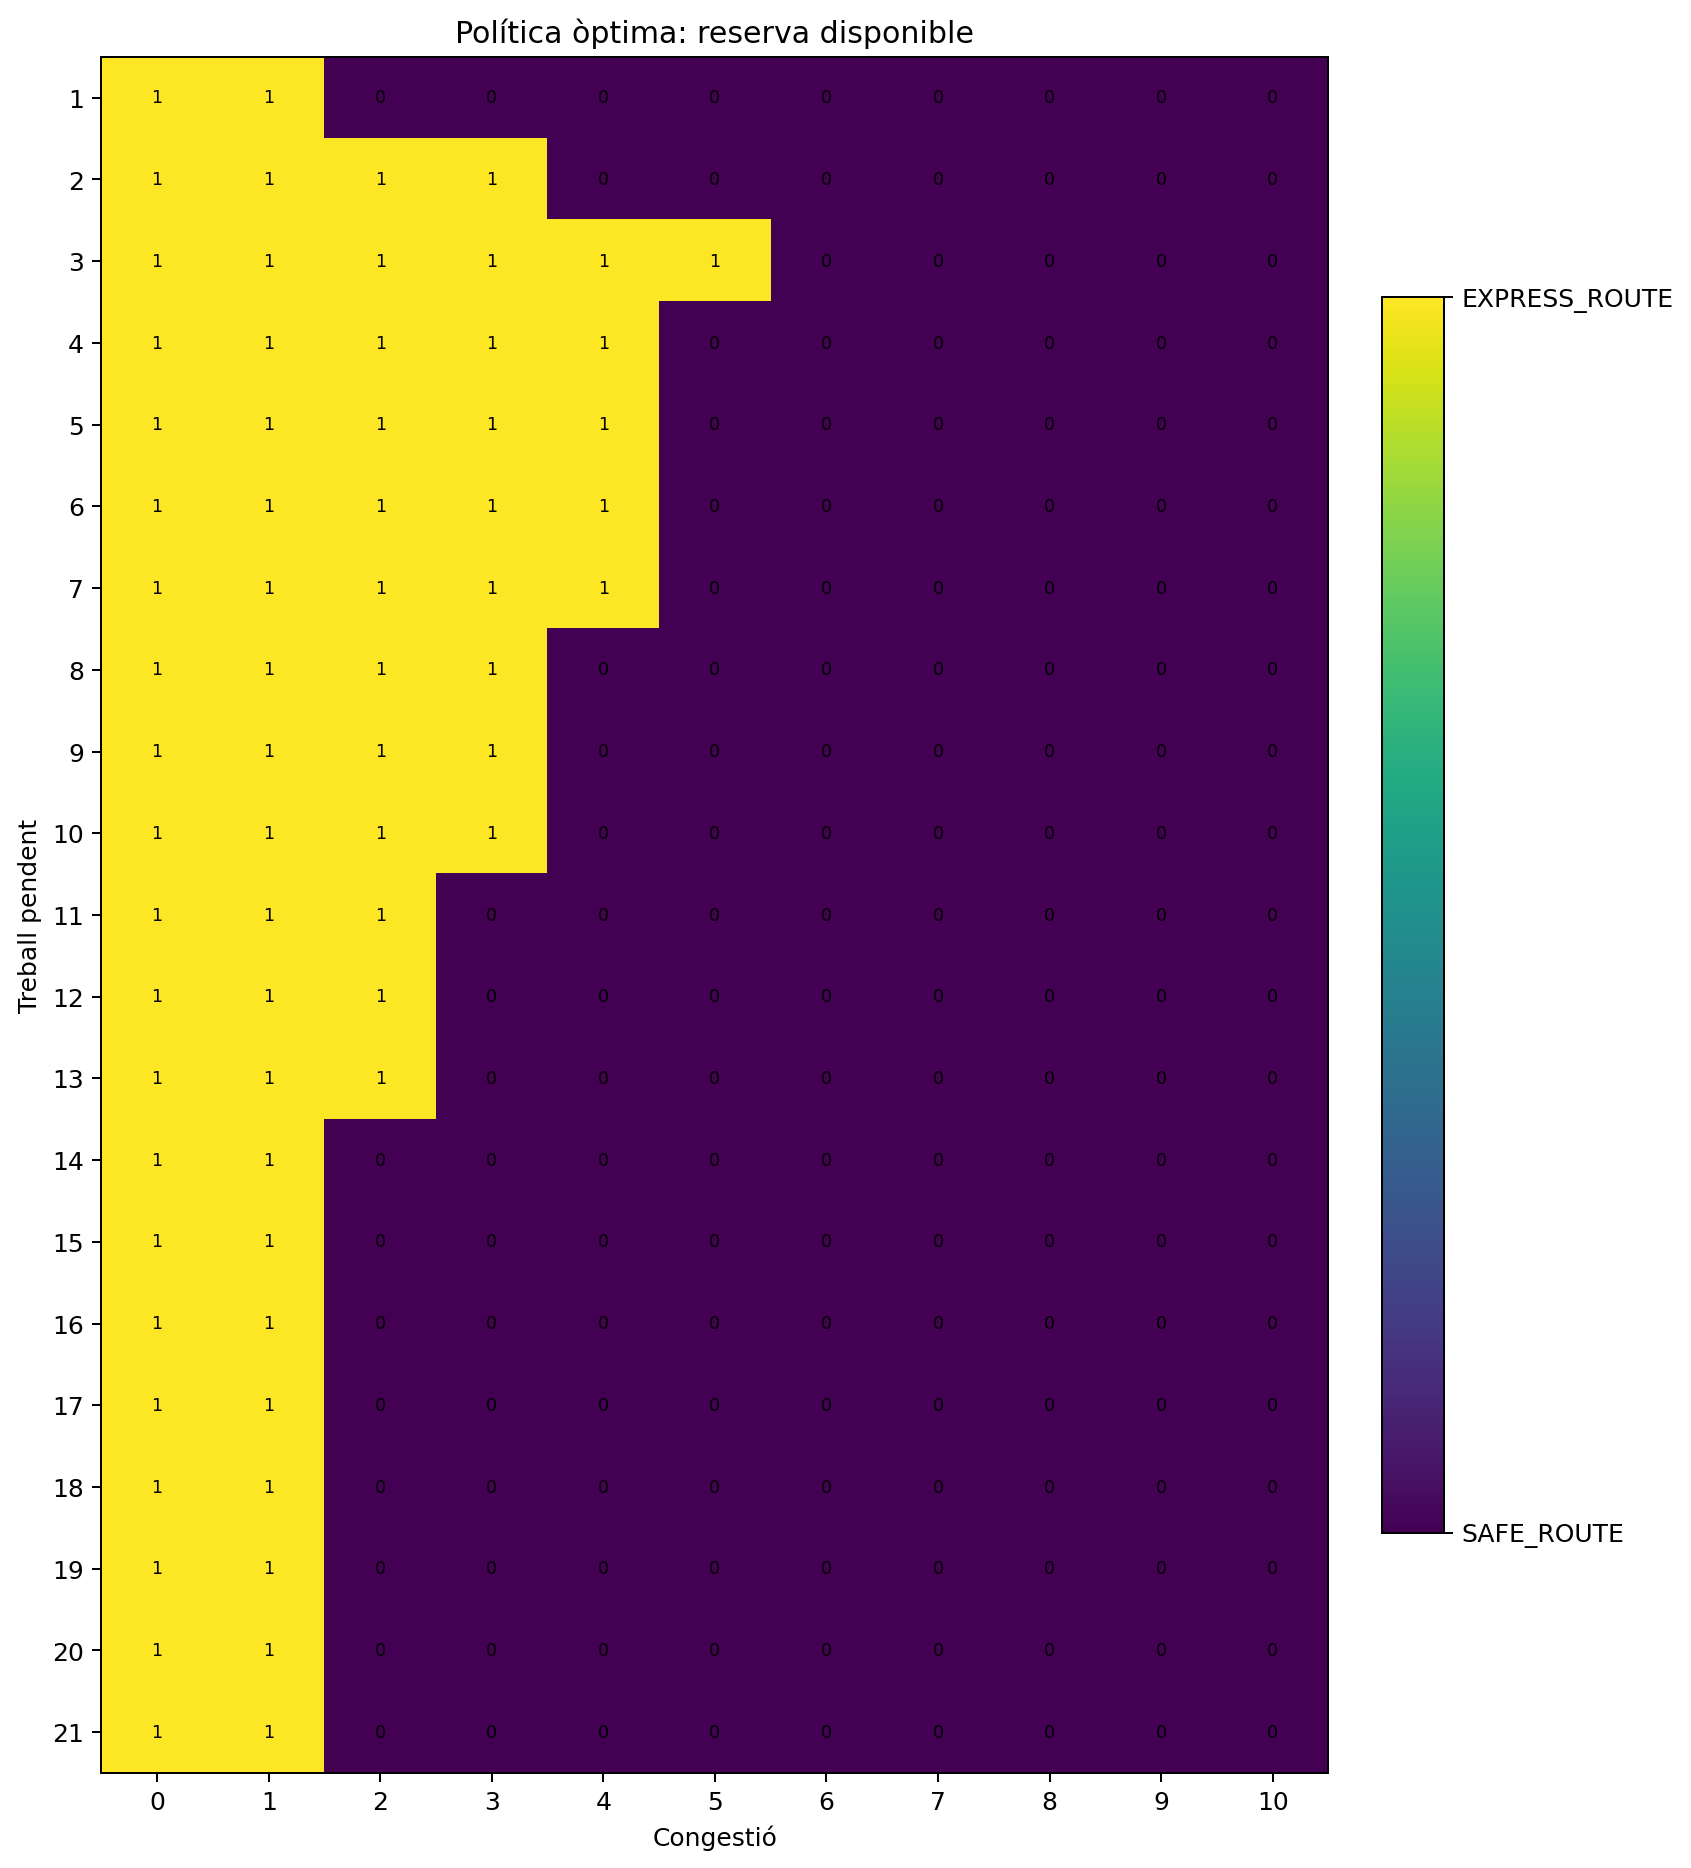

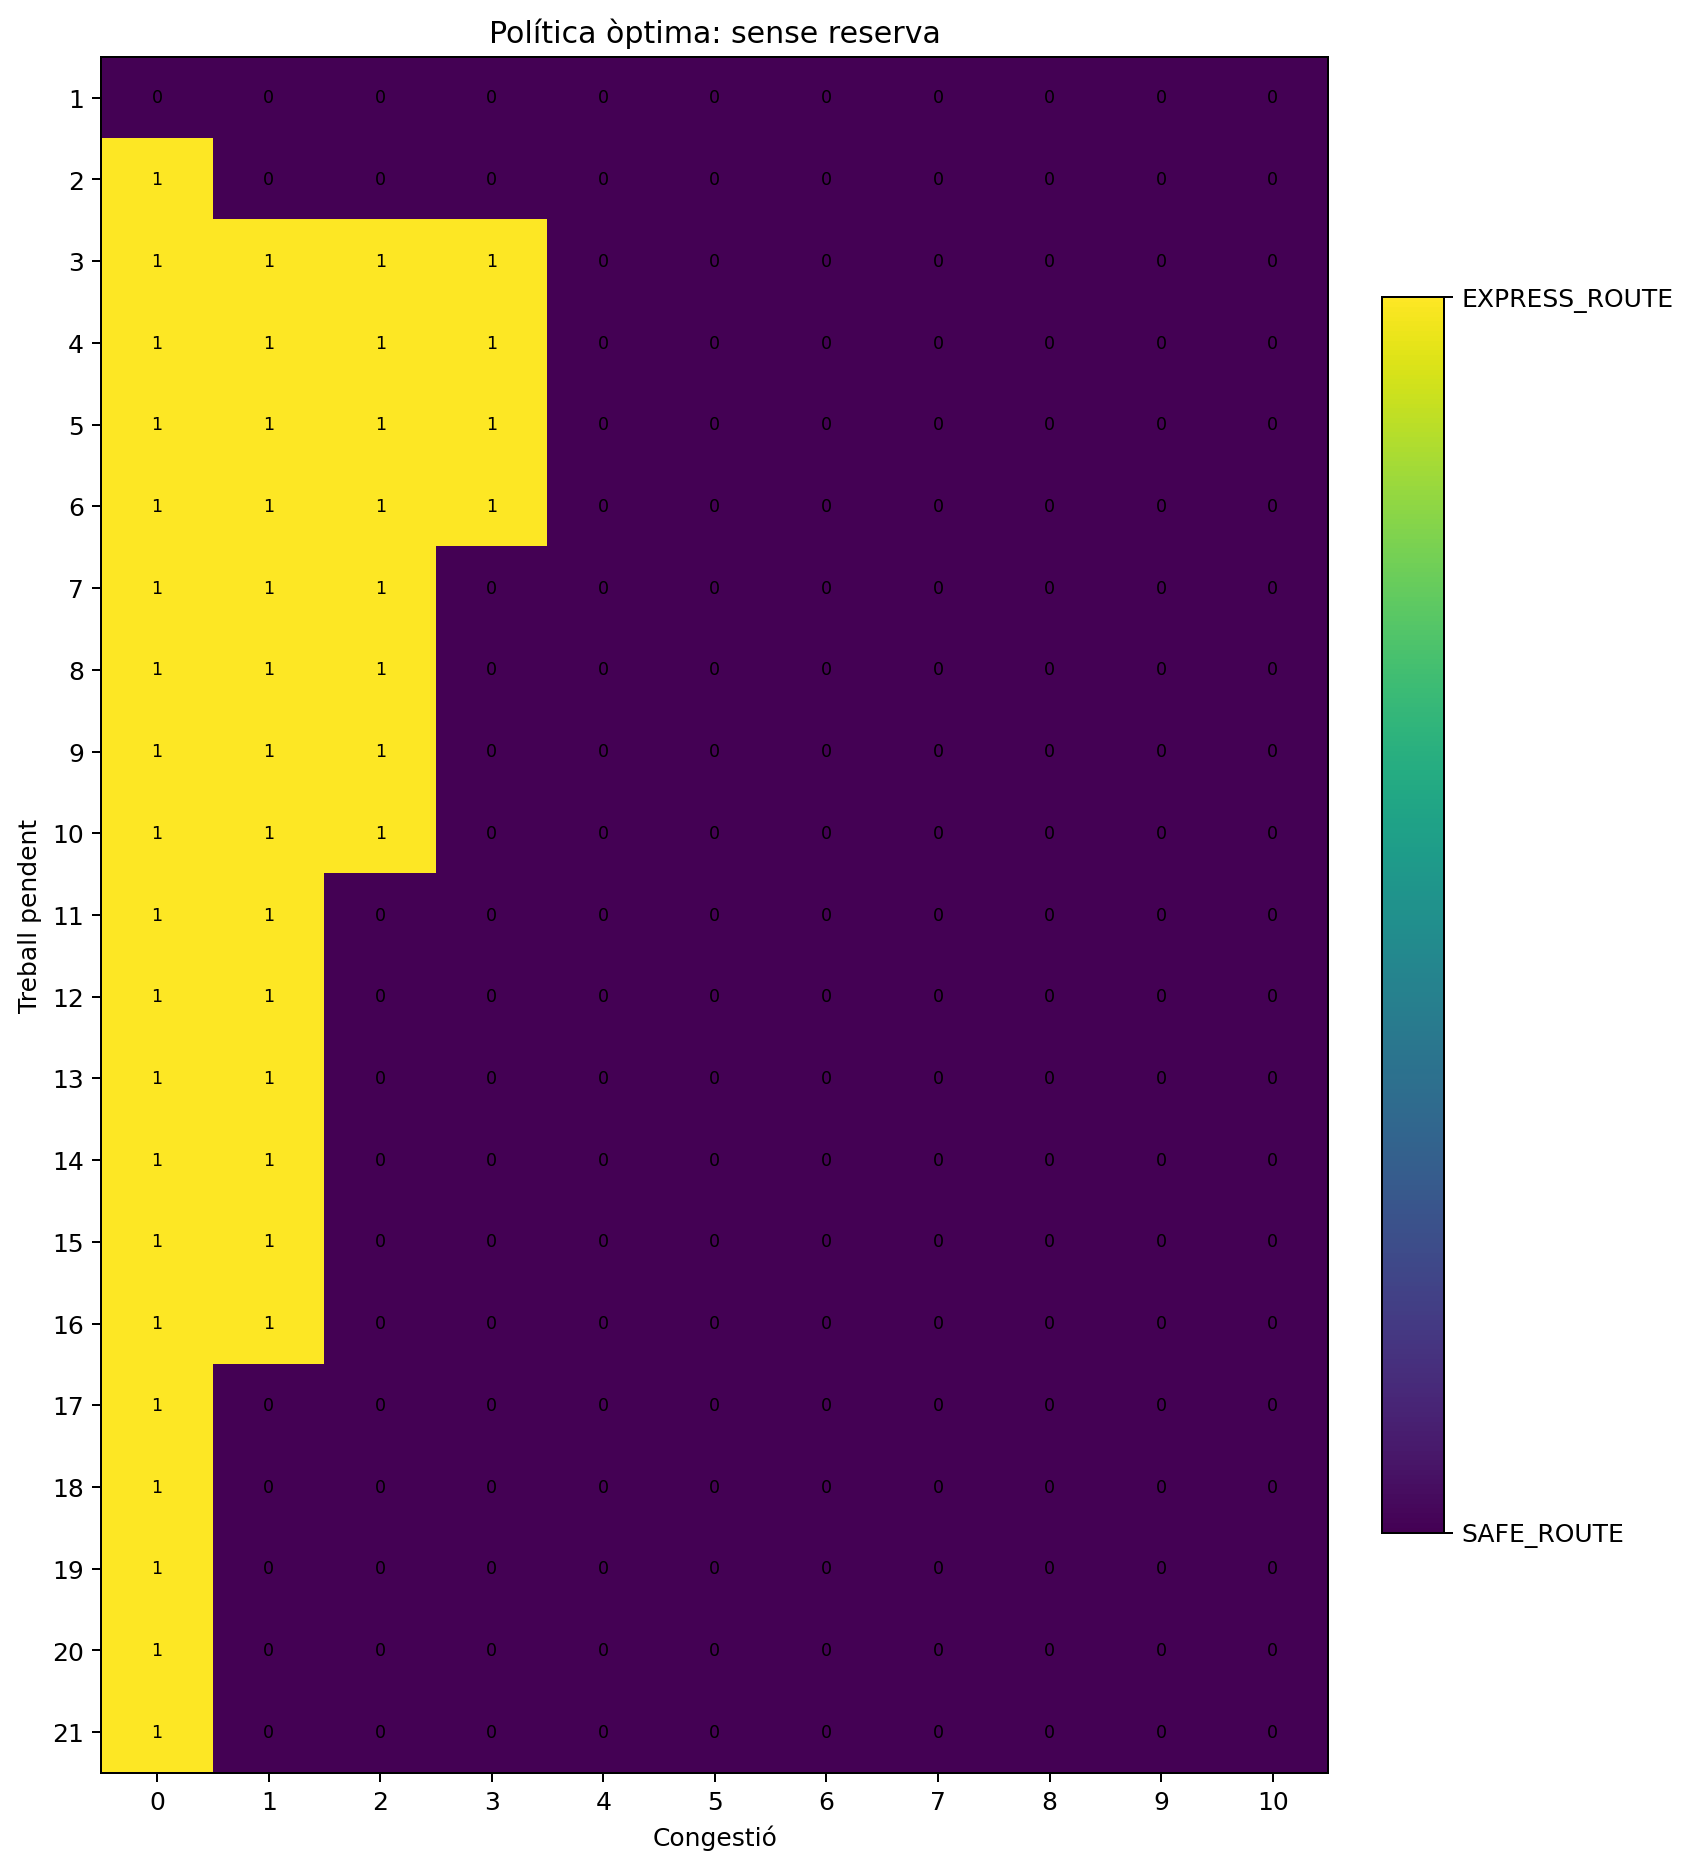

**Figura 2. Política òptima de referència per als estats no terminals de l'entorn, amb reserva disponible i sense reserva.**  
A les figures, **0 = SAFE_ROUTE** i **1 = EXPRESS_ROUTE**.


A continuació us proporcionem alguns escenaris d'exemple extrets de la figura:


| **Reserva** | **Congestió** | **Treball pendent** | **Acció** |
|----------------|------------|----------------|------------|
| Sí             | 2          | 17             | SAFE_ROUTE |
| Sí             | 5          | 17             | SAFE_ROUTE |
| Sí             | 2          | 19             | SAFE_ROUTE |
| Sí             | 1          | 20             | EXPRESS_ROUTE |
| No             | 1          | 12             | EXPRESS_ROUTE |
| No             | 5          | 12             | SAFE_ROUTE |
| No             | 1          | 17             | SAFE_ROUTE |
| No             | 1          | 8              | EXPRESS_ROUTE |


<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Exercici 2.1</strong> (1 punt)</div>

Implementeu un agent que executi la política òptima definida anteriorment. La política ha de contemplar tots els estats no terminals que poden aparèixer durant un episodi (treball pendent entre 1 i 21).



In [22]:
# Inicialitzem l'entorn
env = wh1.WarehouseRoutingEnv()
obs, info = env.reset()
total_reward, done = 0, False

print("Observació inicial: treball pendent = {}, congestió = {}, reserva = {} ".format(obs[0],obs[1],obs[2]))

switch_action = {
        0: "SAFE_ROUTE",
        1: "EXPRESS_ROUTE",
    }

Observació inicial: treball pendent = 19, congestió = 0, reserva = 0 


In [23]:
######################## SOLUCIÓ ###########################
import warehouse_routing_env as wh1



def get_params(r, c, b, action, env_sample = wh1.WarehouseRoutingEnv()):
    """
    Ens dona els valors de _action_parameters() per a una determinada accio i un determinat estat,
    On tenim les probabilitats dels events i les possibilitats de canvi de congestio i progress
    """
    env_sample.remaining_work = r
    env_sample.congestion = c
    env_sample.reserve_available = bool(b)
    return env_sample._action_parameters(action)


In [24]:
get_params(20, 5, 1, 1)

{'incident_probability': 0.046,
 'delay_probability': 0.008,
 'progress_values': array([2, 3, 4]),
 'progress_probabilities': array([0.3, 0.5, 0.2]),
 'reserve_loss_probability': 0.11000000000000001,
 'congestion_changes': array([-1,  0,  1]),
 'congestion_probabilities': array([0.1 , 0.45, 0.45])}

In [25]:
V = {}                  # V[(r, c, b)], millor retorn esperat
optimal_policy = {}     # optimal_policy depen de r, c i b, i es denota com dictionari amb clau (r, c, b)

for r in range(1, 22):
    for c in range(0, 11):
        for b in (0, 1):         # Traversem totes les possibilitats per a les variables clau
            q = [0.0, 0.0]              # q[a], retorn esperat de la accio a que es initizializa en 0 per a cada accio, el definim com prob de cada event multiplicat per la seva recompensa
            for a in (0, 1):            # possibles accions, per tant ara "a" es cada accio i utilitzarem q[a] com en notacio escrita q(s,a) ja que s en aquest cas es igual a (r, c, b)
                p = get_params(r, c, b, a)         # tenim el dictionari resultant de _action_parameters(), es important veure que les variables incident_probability, delay_probability i reserve_loss_probability, nomes dependen de r, c, b i a, per tant hem de fer us de recursivitat per tot le reste
                p_no_event = 1 - p["incident_probability"] - p["delay_probability"] 

                q[a] = p["incident_probability"] * -1         # iniciem q com: prob incident * recompensa incident

                for k, pk in zip(p["progress_values"], p["progress_probabilities"]): # Comencem la recursivitat, hem de calcular que pasa en cada possibilitat de progreso
                    k = int(k)
                    if r - k <= 0:          # aquest es quan arribem a un estat terminal, la recompensa futura es 1, ja que no depen de la reserva
                        future = 1.0                     
                    else:
                        future = 0.0
                        rl = p["reserve_loss_probability"]          # Si no estem en un estat terminal, evaluem per els casos on tenim la reserva o la perdem
                        reserve_outcomes = [(1, 1 - rl), (0, rl)] if b == 1 else [(0, 1.0)] # Si encara tenim reserva hi han 2 escenaris (no perdre-la o perdre-la), si hem perdut, es simplifica perque no es pot guanyar

                        for dc, pc in zip(p["congestion_changes"], p["congestion_probabilities"]):      # Ara evaluem per cadascu els possibles canvis de congestio
                            c_next = min(max(c + int(dc), 0), 10)           # El seguent valor de congestio esta limitat per el rang de valors de congestio, assumim que es dara pero el calcularem mes endavant
                            for b_next, pb in reserve_outcomes:             # Evaluem per cadascu dels valors de la reserva i les seves probabilitats
                                future += pc * pb * V[(r-k, c_next, b_next)]  # Aquesta es la recompensa esperada, que depen de les probabilidades de canvi, perdua de reserva i el seu valor corresponent
                    q[a] += p_no_event * pk * future            # com ja teniem la primera part de q, i com la recompensa per "delay" es 0 no se escriu, ens queda calulcar i actualitzar la variable amb els casos de exit/progress

            V[(r, c, b)] = max(q) # despres de cada iteracio completa de r, c i b, actualitzem V amb el valor mes gran trobat, es a dir la "recompensa optima" per cada estat
            optimal_policy[(r, c, b)] = int(q[1] > q[0]) # asignem la accio preferida, que en cas de igualtat prefereix la opcio segura, per efectes practique no canvia res

In [26]:
# Primers 5 estats del dictionari i les seves recompenses esperades
list(V.items())[:5]

[((1, 0, 0), np.float64(0.948)),
 ((1, 0, 1), np.float64(0.9857)),
 ((1, 1, 0), np.float64(0.944)),
 ((1, 1, 1), np.float64(0.9697)),
 ((1, 2, 0), np.float64(0.94))]

In [27]:
# Primers 5 accions optimes
list(optimal_policy.items())[:5]

[((1, 0, 0), 0),
 ((1, 0, 1), 1),
 ((1, 1, 0), 0),
 ((1, 1, 1), 1),
 ((1, 2, 0), 0)]

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Exercici 2.2</strong> (0,5 punts)</div>

Comprovació de resultats. Implementeu una funció que mostri la política per pantalla per comprovar que l'agent implementat executa correctament la política òptima.

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>NOTA:</strong> Verifiqueu i compareu la política per als estats representats a la figura 2: <strong>treball pendent = 1-21, congestió = 0-10, amb reserva/sense reserva</strong>.</div>


In [28]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def print_policy_opt(policy):
    """
    Per a una politica donada, es crea el heatmap per a cada cas (amb reserva i sense)
    Evidenciant aixi la accio optima en cada cas
    Es crea un pd.DataFrame a partir dels valors de la vaiable policy que es un dictionary amb claus en forma de (r, c, b) per simplicitat, es pot fer amb un array tambe, amb l'intencio de tenir un input de r x c i que sigui facil de mapejar per sns.heatmap
    Com que b es binaria, es crean dos heatmaps (cadascu amb un valor de b), per recrear la imatge donada
    """
    fig, axes = plt.subplots(1, 2, figsize=(14, 9))
    for ax, b, title in zip(axes, (1, 0), ("Amb reserva", "Sense reserva")):
        r_values = [r for r in range(1,22)]
        c_values = [c for c in range(0,11)]
        values = [[policy.get((r, c, b)) for c in c_values] for r in r_values]
        grid = pd.DataFrame(values, index=r_values, columns=c_values)
        sns.heatmap(grid, annot=True, fmt="d", cbar=False, ax=ax)
        ax.set_title(title)
        ax.set_xlabel("Congestió")
        ax.set_ylabel("Treball pendent")
    plt.tight_layout()
    plt.show()

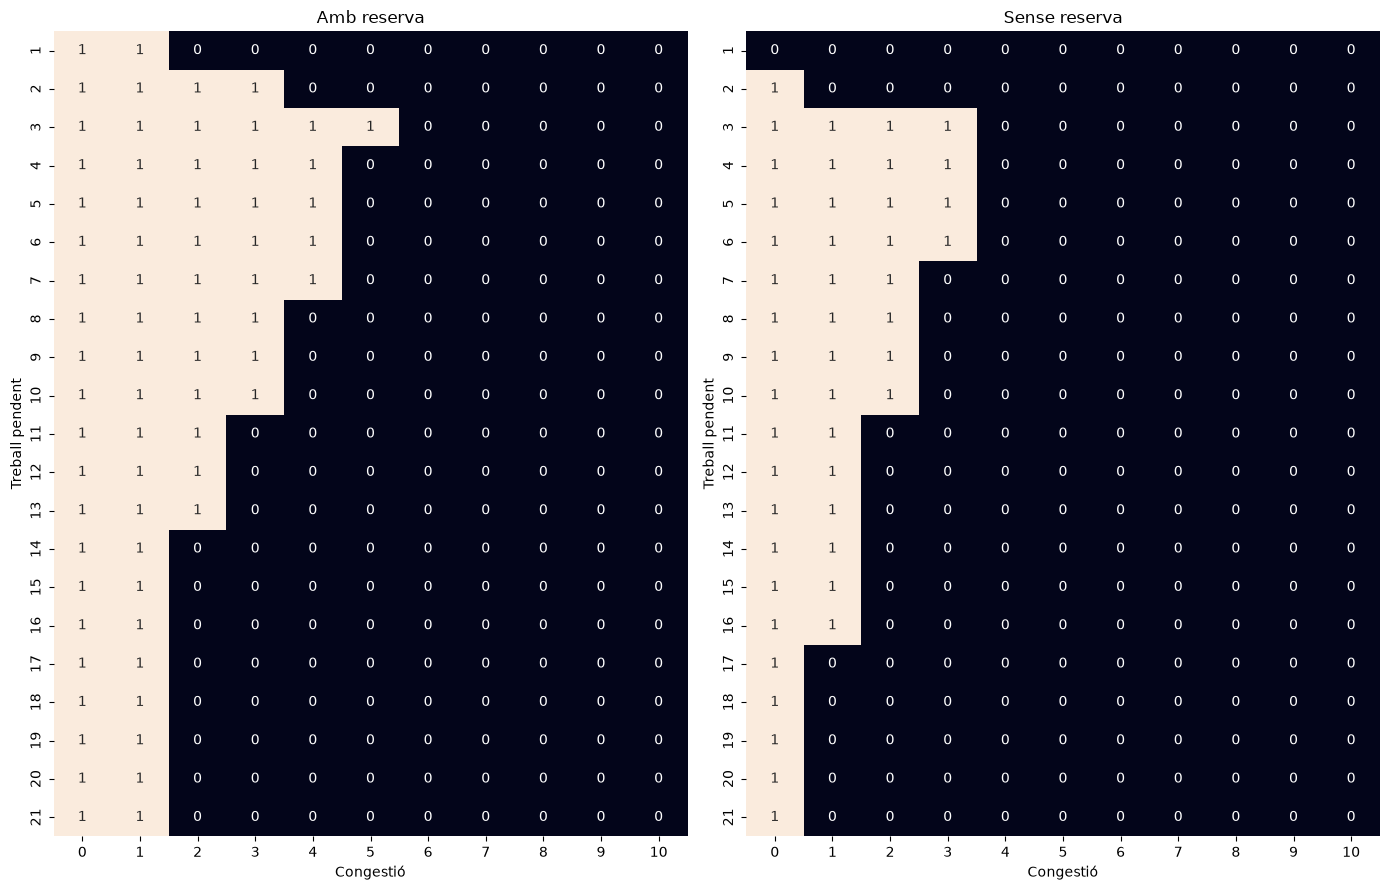

In [29]:
print_policy_opt(optimal_policy)

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Exercici 2.3</strong> (0,5 punts)</div>

Utilitzant l'agent i l'entorn de l'apartat anterior, simuleu 100.000 episodis i calculeu el retorn de l'agent (recompensa total acumulada).

Calculeu el % d'expedicions completades, incidències i retards i comenteu les diferències respecte de la política de l'apartat 1. Quin efecte té la política sobre el compromís entre rapidesa i risc? En comparar els retorns, tingueu en compte que l'apartat 1 utilitza una bonificació d'1,5 i aquest apartat utilitza l'entorn base sense aquesta bonificació.


In [30]:
######################## SOLUCIÓ ###########################

episodes = 100000

inici = time.perf_counter()
_ = run_episodes_heuristic_policy(env=wh1.WarehouseRoutingEnv(), sample_policy=optimal_policy.get, episodes=episodes) # Com tenim la politica optima en un diccionari amb la mateixa estructurea que la funcio del apartat anterior, amb el metode get es suficient per utilitzarla
fi = time.perf_counter()
temps_str = str(timedelta(seconds=fi - inici))[:-4]
print(f"Temps d'execució: {temps_str}")

++++++++++++++++++++++++++++++++++++++++
Resultats
++++++++++++++++++++++++++++++++++++++++
Episodis: 100000
Recompensa total acumulada: 43603.0
Mitjana per episodi: 0.44
% Completades: 58.02%
% Completades Normal: 58.02%
% Completades Priority: 0.00%
++++++++++++++++++++++++++++++++++++++++
% Incidencies: 14.42%
% Retards: 27.57%
++++++++++++++++++++++++++++++++++++++++
Temps d'execució: 0:00:08.48


In [31]:
# Apartat 1, env 1
episodes = 100000

inici = time.perf_counter()
_ = run_episodes_heuristic_policy(env=wh1.WarehouseRoutingEnv(), sample_policy=politica_1_3, episodes=episodes)
fi = time.perf_counter()
temps_str = str(timedelta(seconds=fi - inici))[:-4]
print(f"Temps d'execució: {temps_str}")

++++++++++++++++++++++++++++++++++++++++
Resultats
++++++++++++++++++++++++++++++++++++++++
Episodis: 100000
Recompensa total acumulada: 41267.0
Mitjana per episodi: 0.41
% Completades: 53.94%
% Completades Normal: 53.94%
% Completades Priority: 0.00%
++++++++++++++++++++++++++++++++++++++++
% Incidencies: 12.67%
% Retards: 33.39%
++++++++++++++++++++++++++++++++++++++++
Temps d'execució: 0:00:09.00


<div style="background-color: #fcf2f2; border-color: #dfb5b4; border-left: 5px solid #dfb5b4; padding: 0.5em;">
<strong>Comentaris:</strong>
<br>
Per fer una millor comparacio s'ha realitzat la simulacio de la politica del apartat 1.3 amb el ambient 1, on no tenim el bonus de prioritat, el que es pot verificar amb el % Completades Priority = 0.

Tobem que obtenim una recompensa esperada 0.02 punts major en promedi (0.43) per la politica optima, i tenim mes percentatge de completades que en aquest cas es el principal responsable de la millora. Ja que la politica 1.3 continua tenin molt poques incidencies (menys que l'optima) i mes retards. 

En conclusio, el punt de optimalitat evidenciat en aquest escenari es clarament mes arriesgat que la politica on nomes tomem la accio Express quan hi ha poca congestio i es te la reserva, ja que evidenciem mes incidencies, pero que aquesta regla determinista es solapa amb la politica optima ja que la seva recompensa mitjana per episodi es troba molt a prop de l'optima.
<br>


</div>


<div style="background-color: #c3fac4; border-color: #dfb5b4; border-left: 5px solid #dfb5b4; padding: 0.5em;">
<strong>Fonts:</strong>
<br><br>
Indiqueu aquí les fonts utilitzades en l'elaboració d'aquest exercici.

- Processos de decisió de Markov. Primera edició: setembre 2021 © d'aquesta edició, Fundació Universitat Oberta de Catalunya (FUOC). Autoria: Luis Esteve Elfau. 

- Programació dinàmica. Primera edició: setembre 2021 © d'aquesta edició, Fundació Universitat Oberta de Catalunya (FUOC). Autoria: Paolo Dini

- S'ha utilitzat Claude Sonnet 5.5 (Anthropic) com a suport per a la correcció lingüística i d'estil dels comentaris. La implementació del codi i l'anàlisi són elaborats per l'estudiant

</div>


## 3. Mètodes de Montecarlo (2 punts)

L'objectiu d'aquest apartat és fer una estimació de la política òptima mitjançant els mètodes de Montecarlo. Concretament, estudiarem l'algoritme 2 del mòdul 5: *Control mitjançant mètodes MC amb exploracions inicials*.


<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Exercici 3.1</strong> (1 punt)</div>

Implementeu l'algoritme 2 explicat al mòdul 5 «Mètodes de Montecarlo»: *Control mitjançant mètodes MC amb exploracions inicials (Exploring Starts)*.

**Nota:** En aquesta pràctica s'utilitza una adaptació d'*Exploring Starts* a la dinàmica natural de l'entorn. L'estat inicial es genera mitjançant `env.reset()` segons la distribució definida a l'entorn (treball pendent entre 12 i 21) i la primera acció de cada episodi se selecciona aleatòriament. No cal modificar el comportament de `reset()` per forçar altres estats inicials.

Feu l'entrenament utilitzant els paràmetres següents:

- Nombre d'episodis = 5.000.000
- Factor de descompte = 1

Mesureu el temps d'entrenament i mostreu-lo per pantalla.


In [32]:
######################## SOLUCIÓ ###########################
import numpy as np
import time
from datetime import timedelta

def mc_exploring_starts(env, num_episodes, gamma=1.0, seed=12):
    """
    Comencem per definir i initzializar les variables Q i N, que son arrays de 4 dimensions (r, c, b, a), analogament a la teoria equival a q(s,a) on s (estat) = r, c, b , i la accio a es si mateixa, pel cas de N nomes contarem quantes vegades hem visitat un determinat estat.
    Com initzialitzem Q amb 0, aixo vol dir que la accio per defecte quan ens trobem en un estat nou, sera la accio SAFE
    Assignem una semilla per assegurar la reproductibilitat
    Iterem per a cada episodi, on reseteem l'ambient, el que vol dir que ens trobarem en estats inicials aleatoris definits, i definim variables de soport.
    Utilitzem el mateix codi que als primers apartats per explorar l'episodi amb la diferencia de que la politica sempre toma la primera accio com aleatoria mitjancant la funcio sample() i per tot le reste de passos triem la millor accio definida al array Q
    Una vegada terminat el episodi actualitem els valors de N i Q en funcio de l'obtingut.
    Es comenca per initzialitzar G (el retorn) del episodi en 0, i explorar les observacions, accions i recompenses de cada pas de l'episodi
    Actualitzem G basats en la recompensa i el valor del G futur adjustat pel factor de descopmte (per defecte 1)
    Incrementem en 1 la visita al estat del pas en funcio de la accio tomada (N) i actualitzem el retorn del pas i la accio tomada (Q) amb la mitjana incremental definida a la teoria
    """
    Q = np.zeros((22, 11, 2, 2))      # Q[r, c, b, a]
    N = np.zeros((22, 11, 2, 2))      
    env.reset(seed=seed)
    env.action_space.seed(seed)

    for _ in range(num_episodes):
        obs, _ = env.reset()
        episode, done, first = [], False, True
        while not done:
            if first:
                a = env.action_space.sample()      # exploring start
                first = False
            else:
                a = int(np.argmax(Q[obs]))         # Greedy
            new_obs, reward, terminated, truncated, _ = env.step(a)
            episode.append((obs, a, reward))
            obs, done = new_obs, terminated or truncated

        G = 0.0
        for (s, a, reward) in reversed(episode):
            G = reward + gamma*G
            idx = s + (a,)
            N[idx] += 1
            Q[idx] += (G - Q[idx]) / N[idx]
            

    return Q, N


In [33]:
######################## SOLUCIÓ ###########################

inici = time.perf_counter()
Q_mc, N_mc = mc_exploring_starts(wh1.WarehouseRoutingEnv(), 5_000_000)
print(f"Temps d'entrenament: {str(timedelta(seconds=time.perf_counter() - inici))[:-4]}")

Temps d'entrenament: 0:08:24.94


In [34]:
np.save("Q_mc_5M.npy", Q_mc)         
np.save("N_mc_5M.npy", N_mc) 
# Q_mc = np.load("Q_mc_5M.npy")
# N_mc = np.load("N_mc_5M.npy")

In [35]:
# Convertim Q de monte carlo en la politica
mc_policy = {
    (r, c, b): int(np.argmax(Q_mc[r, c, b]))
    for r in range(1, 22)
    for c in range(0, 11)
    for b in (0, 1)
}

In [36]:
errors = sum(mc_policy[s] != optimal_policy[s] for s in optimal_policy)

In [37]:
errors

120

In [38]:
bad = [s for s in optimal_policy if mc_policy[s] != optimal_policy[s]]
never_tried = sum(1 for s in bad if min(N_mc[s + (0,)], N_mc[s + (1,)]) == 0)
print(len(bad), never_tried)

120 77


<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Exercici 3.2</strong> (0,5 punts)</div>

Implementeu una funció que mostri per pantalla la política final obtinguda per a cada estat.

S'aconsegueix arribar a la política òptima?

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>NOTA:</strong> Per respondre a la pregunta, es recomana implementar una funció que compari la política obtinguda amb la política òptima per als <strong>462 estats no terminals</strong> de la figura 2: <strong>treball pendent = 1-21, congestió = 0-10, amb reserva/sense reserva</strong>, i que indiqui el nombre d'estats en què l'acció seleccionada difereix de la política òptima.</div>


In [39]:
def print_policy_mc(policy):
    """
    Mostra per pantalla la política obtinguda amb Monte Carlo (Exploring Starts) per als 462 estats no terminals (treball pendent, congestió, amb i sense reserva), reutilitzant la funció de visualització de l'apartat 2.2
    """
    print_policy_opt(policy)

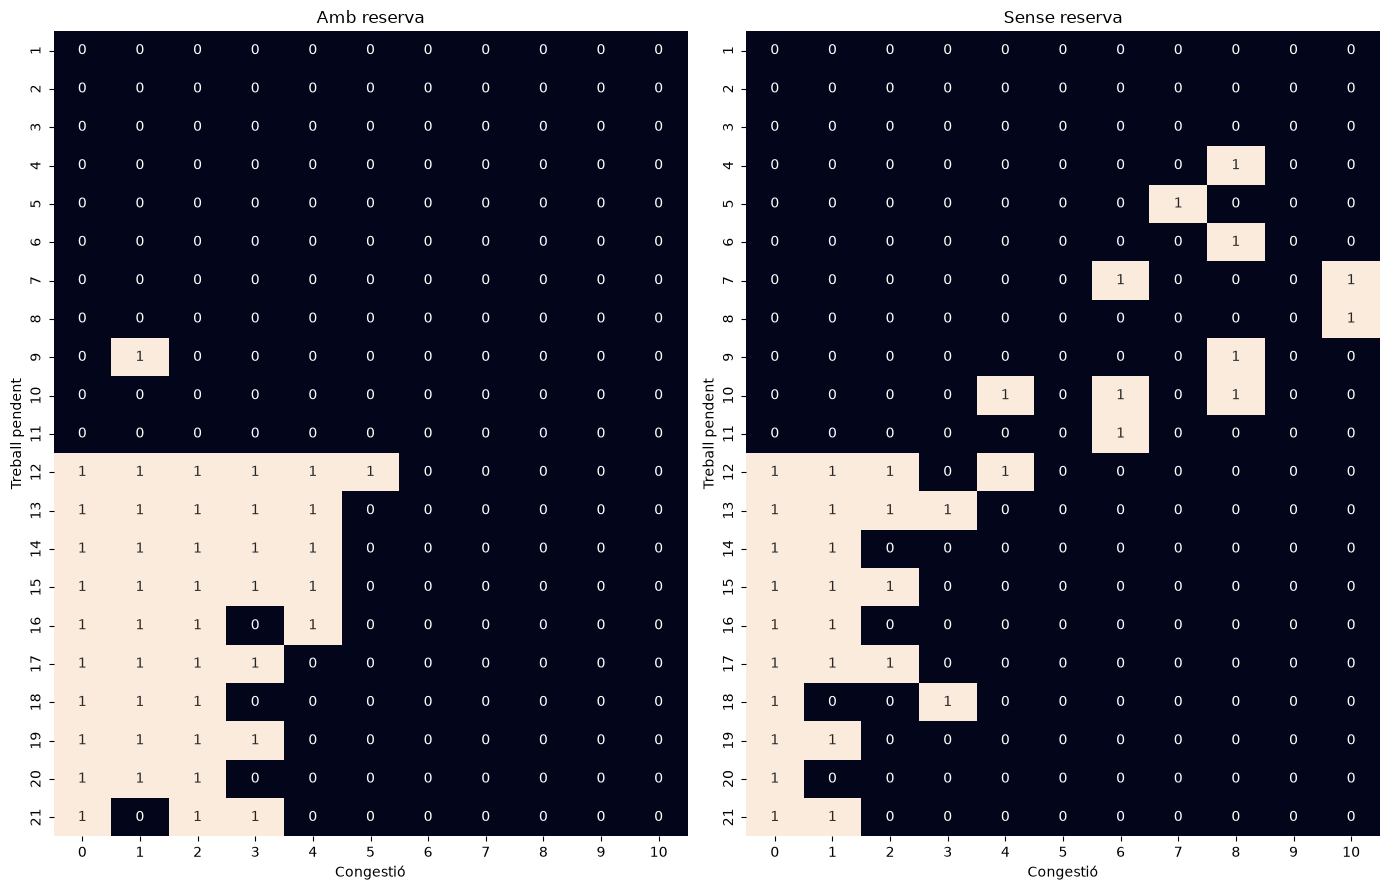

In [40]:
print_policy_mc(mc_policy)

In [41]:
def compara_mc(policy):
    """
    Compara la política donada amb la política òptima (optimal_policy) i retorna
    el nombre d'estats, sobre els 462 no terminals, en què l'acció difereix.

    Paràmetres:
        policy: diccionari {(treball_pendent, congestió, reserva): acció}.
    Retorna:
        int: nombre d'estats amb una acció diferent de l'òptima.
    """
    return sum(policy[s] != optimal_policy[s] for s in optimal_policy)

In [42]:
errors = compara_mc(mc_policy)
print("Nombre total d'errors = {}".format(errors))

Nombre total d'errors = 120


<div style="background-color: #fcf2f2; border-color: #dfb5b4; border-left: 5px solid #dfb5b4; padding: 0.5em;">
<strong>Comentaris:</strong>
<br>
Podem veure, que mitjancant el metode de monte calo, no arribem a la politica optima amb 5M de iteracions, com es pot comprovar visualment a les grafiques i amb el nombre de errors.
Aquest errors poden explicarse ja que initzialitzem amb ceros i quan sempre que es tenen els mateixos valors de Q per a dos accions, triem la accio SAFE, i a mes, per construccio en "exploring starts" nomes donem aleatoriedad al primer pas, el que potser no ens permet explorar altres estats menys probables, que es el que veiem a les grafiques. Ja que la restriccio de que r ha de comenzar en valors mes grans que 11, arribar a estats aleatoriament de trevall pendent <12 es poc probable i per tant actualitzar la politica de base tambe ho es.

Finalment, algunes opcions per probar si en aquest escenari tendriem una major proximitat a la solucio optima es intentar amb un estat inicial mes optimista per Q (per defecte triar la accio 1) o tenir un factor de descompte mes petit.
<br>


</div>


<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Exercici 3.3</strong> (0,5 punts)</div>

Utilitzant l'agent obtingut mitjançant el mètode de MC, simuleu 100.000 episodis i calculeu el retorn de l'agent (recompensa total acumulada).

Calculeu el % d'expedicions completades, incidències i retards i compareu-los amb els de l'apartat 2. A què es deuen les possibles diferències?


In [43]:
######################## SOLUCIÓ ###########################

episodes = 100000

inici = time.perf_counter()
_ = run_episodes_heuristic_policy(env=wh1.WarehouseRoutingEnv(), sample_policy=mc_policy.get, episodes=episodes)
fi = time.perf_counter()
temps_str = str(timedelta(seconds=fi - inici))[:-4]
print(f"Temps d'execució: {temps_str}")

++++++++++++++++++++++++++++++++++++++++
Resultats
++++++++++++++++++++++++++++++++++++++++
Episodis: 100000
Recompensa total acumulada: 40060.0
Mitjana per episodi: 0.40
% Completades: 54.10%
% Completades Normal: 54.10%
% Completades Priority: 0.00%
++++++++++++++++++++++++++++++++++++++++
% Incidencies: 14.04%
% Retards: 31.86%
++++++++++++++++++++++++++++++++++++++++
Temps d'execució: 0:00:09.46


<div style="background-color: #fcf2f2; border-color: #dfb5b4; border-left: 5px solid #dfb5b4; padding: 0.5em;">
<strong>Comentaris:</strong>
<br>

Com s'esperaba, la politica obtinguda a partir de la aproximacio de monte carlo no es optima i per tant la recompensa mitjana per episodi es mes baixa (0.02), el cual es el cas tambe de amb respecte a la politica de la seccio 1, on tenim un rendiment similar.

Com s'ha mencionat abans, el potencial motiu de aquesta differencia amb la politia optima, es probablement que per a certs estats poc explorats, se tria una ruta pitjor, i es probable que amb mes aleatorietat es trobi la ruta correcta, tot i que s'ha de mencionar que el resultat obtingut es aceptable, debut probablement a que els estats poc visitats tenen un impacte limitat i per tant aquest 128 errors sobre 462 estats realment tenen una importancia menor del esperat inicialment.

Podem veure que amb la politica obtinguda amb el metode Monte Carlo, tenim mes retards que l'optima el que confirma la prevalencia de triar SAFE, quan a vegades la politica EXPRESS potser l'optim.

<br>


</div>


<div style="background-color: #c3fac4; border-color: #dfb5b4; border-left: 5px solid #dfb5b4; padding: 0.5em;">
<strong>Fonts:</strong>
<br><br>
Indiqueu aquí les fonts utilitzades en l'elaboració d'aquest exercici.

- Mètodes de Montecarlo. Primera edició: setembre 2021 © d'aquesta edició, Fundació Universitat Oberta de Catalunya (FUOC). Autoria: Luis Esteve Elfau

- Programació dinàmica. Primera edició: setembre 2021 © d'aquesta edició, Fundació Universitat Oberta de Catalunya (FUOC). Autoria: Paolo Dini

- S'ha utilitzat Claude Sonnet 5.5 (Anthropic) com a suport per a la correcció lingüística i d'estil dels comentaris. La implementació del codi i l'anàlisi són elaborats per l'estudiant

</div>


## 4. Mètodes de diferència temporal (2 punts)

L'objectiu d'aquest apartat és fer una estimació de la política òptima mitjançant els mètodes de diferència temporal en l'entorn WarehouseRouting comentat anteriorment.


<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Exercici 4.1</strong> (1,5 punts)

Implementeu l'algoritme *SARSA* explicat al mòdul 6 «Aprenentatge per diferència temporal» i entreneu-lo utilitzant els paràmetres següents (1 punt):
    
- Nombre d'episodis = 5.000.000
- Taxa d'aprenentatge (*learning rate*) = 0.001
- Factor de descompte (*discount factor*) = 1
- *epsilon* = 1/(núm. d'episodi)
- Valor mínim d'*epsilon* = 0.2
<br>
Mesureu el temps d'entrenament i mostreu-lo per pantalla.
<br>
Mostreu una gràfica amb l'evolució de l'error TD màxim de cada episodi (0,5 punts).</div>


In [44]:
######################## SOLUCIÓ ###########################

from collections import defaultdict
import numpy as np

# Carreguem l'entorn
env = wh1.WarehouseRoutingEnv()
print("Espai d'accions: {} ".format(env.action_space))
print("Espai d'observacions: {} ".format(env.observation_space))

Espai d'accions: Discrete(2) 
Espai d'observacions: Tuple(Discrete(22), Discrete(11), Discrete(2)) 


In [45]:
######################## SOLUCIÓ ###########################

def sarsa(env, num_episodes, alpha=0.001, gamma=1.0, eps_min=0.2, seed=12):
    """
    Comencem la implementacio de l'algoritme SARSA mitjancant la initzialitzacio de variables i asignacio de semilles per assegurar la reproductibilitat
    Initzialitzem un altre vegade Q amb ceros i initizialitzem deltas tambe amb zeros per el nombre de episodis
    Iterem per cada episodi i ajustem el valor de epsilon, que sera gran al inici pero es mantendra constant (amb el valor eps_min) una vegade incrementem el numero de episodis
    Reinitzialitzem el ambient i assignem els valors de estat a la vaiable s.
    Utilitzant la funcio de soport definim la propera accio e iniciem el loop de cada episodi de forma similar a com s'ha fet al transcurs de la pac
    Per cada pas assignem les variables i quan ens trobem en un estat terminal el valor objectiu es el mateix que la recompensa, per contra si no estem en un estat terminal, triem la seguent accio mitjancant la funcio de suport i assignem el objectiu
    En aquest cas, el objectiu d'accord amb la teoria sera la recompensa futura esperada ajustada temporalment amb el factor de descompte gamma 
    Asignem a la variable delta el valor de la diferencia entre el objectiu (definit amunt) i el retorn esperat actual, i actualitzem el retorn esperat actual per aquest delta adjustat per el parametre alpha (com una meda de "gradient descent")
    Finalment reasignem les variables de estat i accio per al seguent pas i recalculem el delta maxim que sera enregistrat al final del episodi
    La funcio retorna Q i la llista de deltas
    """
    rng = np.random.default_rng(seed)
    env.reset(seed=seed)
    Q = np.zeros((22, 11, 2, 2))             # Q[r, c, b, a]
    deltas = np.zeros(num_episodes)          # max TD error per episodi

    def eps_greedy(s, eps):
        """
        Funcio de suport per retornar una accio aleatoria (numero aleatori) quan el valor generat aleatori sigui menor que el parametre epsilon (eps)
        En cas de no cumplirse aquesta condicio es retornara la accio asociada al valor amb el retorn esperat mes gran
        """
        if rng.random() < eps:
            return int(rng.integers(2))
        return int(np.argmax(Q[s]))

    for ep in range(1, num_episodes + 1):
        eps = max(1 / ep, eps_min)
        s, _ = env.reset()
        a = eps_greedy(s, eps)
        done, max_delta = False, 0.0
        while not done:
            s2, r, terminated, truncated, _ = env.step(a)
            done = terminated or truncated
            if done:
                a2 = None
                target = r                  
            else:
                a2 = eps_greedy(s2, eps)
                target = r + gamma * Q[s2+(a2,)]                  
            delta = target - Q[s + (a,)]
            Q[s + (a,)] += alpha * delta
            max_delta = max(max_delta, abs(delta))
            s, a = s2, a2
        deltas[ep - 1] = max_delta
    return Q, deltas

In [46]:
######################## SOLUCIÓ ###########################

env = wh1.WarehouseRoutingEnv()
inici = time.perf_counter()
Q_sarsa, deltas = sarsa(env, 5_000_000, alpha=0.001, gamma=1.0, eps_min=0.2)
print(f"Temps d'entrenament: {str(timedelta(seconds=time.perf_counter() - inici))[:-4]}")
np.save("Q_sarsa_5M.npy", Q_sarsa)
np.save("deltas_5M.npy", deltas)

Temps d'entrenament: 0:07:58.77


In [68]:
######################## SOLUCIÓ ###########################

# Q_sarsa

In [69]:
# deltas

In [49]:
window = 1000
average_deltas = []
inici = time.perf_counter()
for idx in range(len(deltas) - window + 1):
    average_deltas.append(np.mean(deltas[idx:idx+window]))
fi = time.perf_counter()
temps_str = str(timedelta(seconds=fi - inici))[:-4]
print("")
print(f"Temps d'execució: {temps_str}")


Temps d'execució: 0:00:07.75


/tmp/ipykernel_101752/1646561887.py:8: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/usr/local/lib/python3.11/site-packages/IPython/core/events.py:101: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)
/usr/local/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


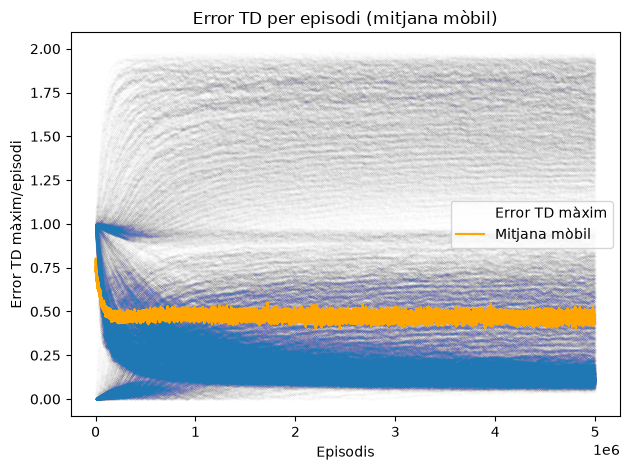

In [50]:
plt.subplot()
plt.title("Error TD per episodi (mitjana mòbil)")
plt.scatter(range(1,len(average_deltas)+1), deltas[0:len(deltas) - window + 1],  s=0.0001, alpha=0.2)
plt.plot(range(1,len(average_deltas)+1), average_deltas, color='orange')
plt.xlabel('Episodis')
plt.ylabel('Error TD màxim/episodi')
plt.legend(['Error TD màxim', 'Mitjana mòbil'])
plt.tight_layout()

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Exercici 4.2</strong> (0,25 punts)</div>

Implementeu una funció que mostri per pantalla la política apresa mitjançant SARSA per a cada estat.

S'aconsegueix arribar a la política òptima?

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>NOTA:</strong> Per respondre a la pregunta, es recomana implementar una funció que compari la política obtinguda amb la política òptima per als estats de la figura 2: <strong>treball pendent = 1-21, congestió = 0-10, amb reserva/sense reserva</strong>, i que indiqui el nombre d'accions no òptimes (si n'hi ha).</div>


In [51]:
def q_to_policy(Q):
    """
    Converteix una taula Q[r, c, b, a] en un diccionari de política
    """
    return {(r, c, b): int(np.argmax(Q[r, c, b]))
            for r in range(1, 22) for c in range(11) for b in (0, 1)}

In [52]:
def print_policy_SARSA(q):
    """
    Reutilitzem la funcio definida anteriorment per a mostrar la politica en pantallas
    """
    print_policy_opt(q_to_policy(q))

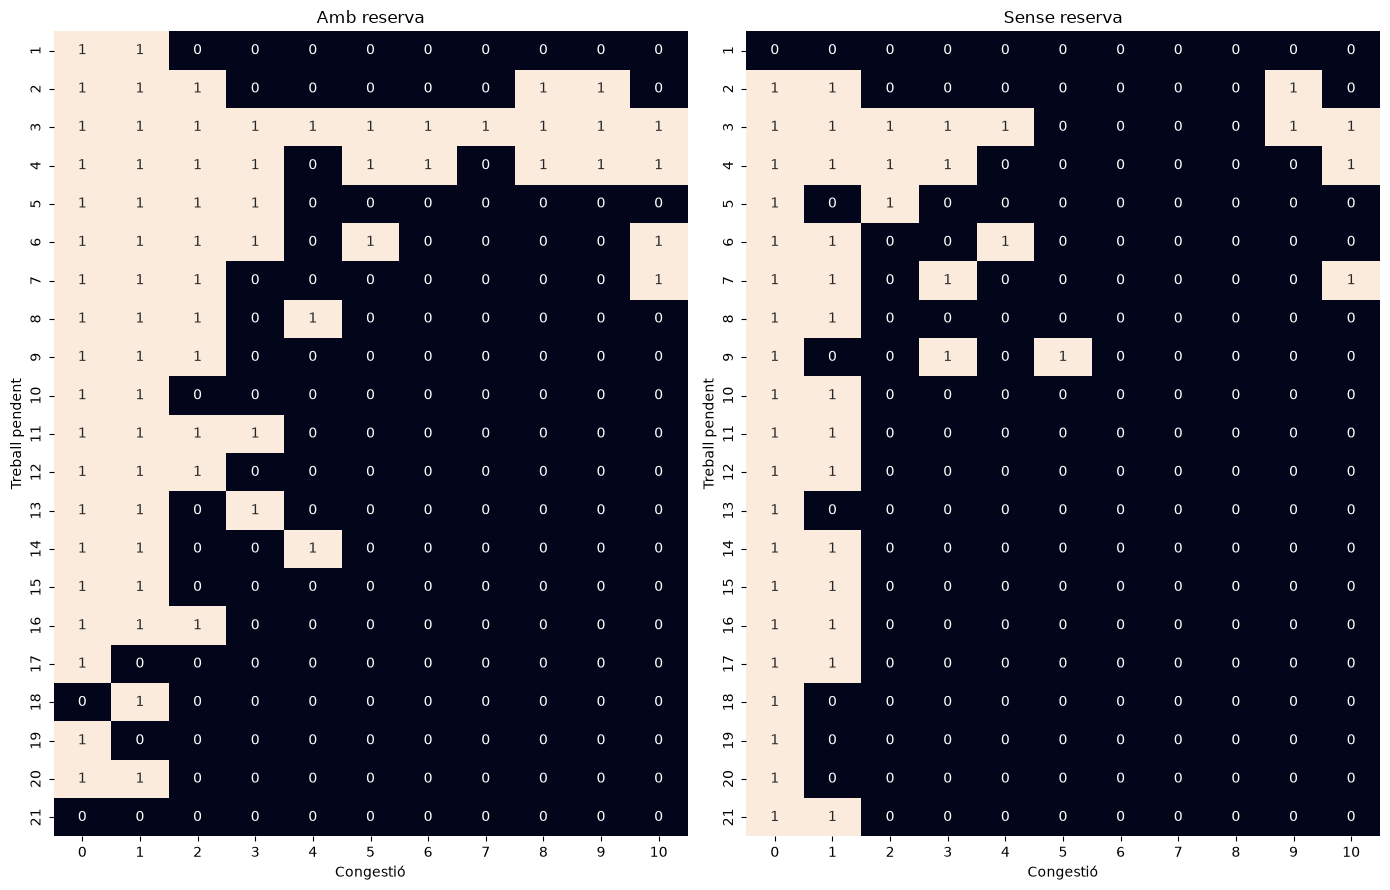

In [53]:
print_policy_SARSA(Q_sarsa)

In [54]:
def compara_sarsa(q):
    """
    Retorna el nombre d'estats on la política SARSA difereix de l'optima
    """
    pol = q_to_policy(q)
    return sum(pol[s] != optimal_policy[s] for s in optimal_policy)

In [55]:
errors = compara_sarsa(Q_sarsa)
print("Nombre total d'errors = {}".format(errors))

Nombre total d'errors = 59


<div style="background-color: #fcf2f2; border-color: #dfb5b4; border-left: 5px solid #dfb5b4; padding: 0.5em;">
<strong>Comentaris:</strong>
<br>
En aquest cas, amb l'algorisme SARSA tampoc hem aconseguit arribar a la politica optima, hem trobat menys errors que en el escenari amb la politica obtinguda a partir de Monte Carlo. 

No obstant veiem comportaments differents en comparacio a Monte Carlo, tot i que clarament es segeuix triant preferiblement la accio SAFE. Per l'algorisme SARSA veriem que es tria la accio EXPRESS amb aparent aleatorietat per valors alts de trevall restant i de congestio, a mes veiem comportaments relativament similars a la politica optima, on hi ha mes accions EXPRESS per als casos amb reserva.

A priori, podriam esperar un rendiment millor a la politica anterior, pero encara a sota de la politica optima.

<br>


</div>


<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Exercici 4.3</strong> (0,25 punts)</div>

Utilitzant l'agent obtingut mitjançant el mètode SARSA, simuleu 100.000 episodis i calculeu el retorn de l'agent (recompensa total acumulada).

S'aprecien grans diferències en els percentatges d'expedicions completades, retards i incidències obtinguts? A què es deu?


In [56]:
######################## SOLUCIÓ ###########################

def run_episodes_sarsa(env, q, num_episodes):
    """
    Executa num_episodes amb la política voraç de q (sense aprendre) i mostra estadístiques
    """
    return run_episodes_heuristic_policy(env, q_to_policy(q).get, num_episodes)

In [57]:
inici = time.perf_counter()
_ = run_episodes_sarsa(env, Q_sarsa, num_episodes=100000)
fi = time.perf_counter()
temps_str = str(timedelta(seconds=fi - inici))[:-4]
print(f"Temps d'execució: {temps_str}")

++++++++++++++++++++++++++++++++++++++++
Resultats
++++++++++++++++++++++++++++++++++++++++
Episodis: 100000
Recompensa total acumulada: 42885.0
Mitjana per episodi: 0.43
% Completades: 57.21%
% Completades Normal: 57.21%
% Completades Priority: 0.00%
++++++++++++++++++++++++++++++++++++++++
% Incidencies: 14.33%
% Retards: 28.46%
++++++++++++++++++++++++++++++++++++++++
Temps d'execució: 0:00:08.55


<div style="background-color: #fcf2f2; border-color: #dfb5b4; border-left: 5px solid #dfb5b4; padding: 0.5em;">
<strong>Comentaris:</strong>
<br>

Com s'esperaba hem obtingut una recompensa mitjana per episodi una mica mes baixa que amb la politica optima, tot i que en aquest escenari clarament es trien accions EXPRESS de manera mes frequent, el que ens porta a que teim menys retards que en les politiques anteriors, pero a la vegade es te un percentatge mes elevat incidencies es molt similar, tenin una mica mes de retards, el que vol dir que la diferencia principal es que la politica optima obte completades normal quan aquesta obte retards, per alguns casos.

<br>


</div>


<div style="background-color: #c3fac4; border-color: #dfb5b4; border-left: 5px solid #dfb5b4; padding: 0.5em;">
<strong>Fonts:</strong>
<br><br>
Indiqueu aquí les fonts utilitzades en l'elaboració d'aquest exercici.

- Mètodes de diferència temporal. Primera edició: setembre 2021 © d'aquesta edició, Fundació Universitat Oberta de Catalunya (FUOC). Autoria: Paolo Dini

- S'ha utilitzat Claude Sonnet 5.5 (Anthropic) com a suport per a la correcció lingüística i d'estil dels comentaris. La implementació del codi i l'anàlisi són elaborats per l'estudiant

<br>
</div>


## 5. Comparativa dels algoritmes (2 punts)

En aquest apartat farem una comparativa entre els algoritmes.

Compararem el comportament dels algoritmes en modificar els valors del nombre d'episodis, el factor de descompte i la taxa d'aprenentatge (*learning rate*) en el cas del mètode SARSA.

Per a cada exercici s'han de mostrar i justificar els resultats.

<u>NOTA</u>: feu 3 execucions independents per configuració, atès el caràcter aleatori de les simulacions, i presenteu la mitjana dels resultats. Per tal que les execucions siguin reproduïbles i comparables, utilitzeu les llavors **42, 123 i 2026**, una per a cadascuna de les tres execucions.


<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Exercici 5.1 - Influència del nombre d'episodis</strong> (1 punt)</div>

Feu un estudi modificant el nombre d'episodis en cadascun dels 2 algoritmes:
- Entreneu cada algoritme amb 100.000, 300.000 i 1.000.000 d'episodis, feu 3 execucions per configuració i calculeu la mitjana dels resultats.
- Indiqueu com influeix el nombre d'episodis en la convergència de cada algoritme, calculant el nombre d'estats en què la política difereix de l'òptima sobre els **462 estats no terminals de la figura 2**, així com la mitjana del retorn obtingut en executar 100.000 episodis després de cada entrenament.
- Indiqueu també com afecta el nombre d'episodis al temps d'entrenament.

Nota: trieu el format adequat per presentar els resultats (taula, gràfica de punts, diagrama de barres, ...) de manera que doni suport a les explicacions realitzades.


In [58]:
######################## SOLUCIÓ ###########################
policies = {}   # (algo, episodes, gamma, alpha, seed) -> policy dict

def experiment(algo, num_episodes, seed, **kw):
    """
    Entrena un agent mitjançant algorismes ('mc' o 'sarsa') i l'avalua amb episodis determinats sobre l'entorn base.
    Començem per initialitzar el ambient i assignar gamma.
    En funcion del parametre "algo" utilitzarem els algorismes 'mc' or 'sarsa' amb la seva respectiva funció i ens quedarem amb la funcio de valor estat accio Q obtinguda
    Convertim la funcio al dict de la politica, que toma com claus el estat i la accio, i enregistrem localment en la variable "policies" la el dict de la politica.
    Calculem els errors o les diferencies vs la politica optima
    Finalment, fem la evaluació de la politica en 100.000 episodis.
    Retorna el dict amb la configuració, els errors respecte a la política òptima, la recompensa mitjana per episodi i el temps d'entrenament.
    """
    gamma = kw.get("gamma", 1.0)
    env = wh1.WarehouseRoutingEnv()

    t0 = time.perf_counter()
    if algo == "mc":
        Q, _ = mc_exploring_starts(env, num_episodes, seed=seed, **kw)
    else:
        Q, _ = sarsa(env, num_episodes, seed=seed, **kw)
    train_time = time.perf_counter() - t0

    pol = q_to_policy(Q)
    policies[(algo, num_episodes, gamma, kw.get("alpha"), seed)] = pol
    errors = sum(pol[s] != optimal_policy[s] for s in optimal_policy)

    eval_env = wh1.WarehouseRoutingEnv()
    eval_env.reset(seed=seed)
    res = run_episodes_heuristic_policy(eval_env, pol.get, 100_000, verbose=False)

    return {"algo": algo, "episodes": num_episodes, "seed": seed, "gamma": gamma,
            "alpha": kw.get("alpha"), "errors": errors,
            "mean_return": res["mean_return"], "train_time": train_time}

In [59]:
rows = []
for algo in ("mc", "sarsa"):
    for n in (100_000, 300_000, 1_000_000):
        for seed in (42, 123, 2026):
            rows.append(experiment(algo, n, seed))
            pd.DataFrame(rows).to_csv("results_5_1.csv", index=False)
df = pd.DataFrame(rows)
summary = df.groupby(["algo", "episodes"])[["errors", "mean_return", "train_time"]].agg(["mean", "std"])

In [60]:
summary

errors           mean_return           train_time  \
                      mean       std        mean       std       mean   
algo  episodes                                                          
mc    100000    163.000000  4.358899    0.392590  0.004079   9.685711   
      300000    146.333333  9.018500    0.397250  0.003279  29.002393   
      1000000   126.000000  2.000000    0.403993  0.005035  98.535276   
sarsa 100000    137.000000  3.000000    0.400910  0.002422   9.162263   
      300000    124.666667  4.041452    0.406130  0.001958  29.117473   
      1000000   112.000000  4.358899    0.408947  0.001669  94.914965   

                          
                     std  
algo  episodes            
mc    100000    0.067210  
      300000    0.342040  
      1000000   1.470310  
sarsa 100000    0.099015  
      300000    1.881006  
      1000000   1.305074

<div style="background-color: #fcf2f2; border-color: #dfb5b4; border-left: 5px solid #dfb5b4; padding: 0.5em;">
<strong>CONCLUSIONS:</strong>
<br>

Podem veure que tant per els algrismes de Monte Carlo com per SARSA, a medida que puja el nombre de episodis els errors mitjans baixan, el que vol qui que estan mes a prop de la politica optima i com s'espera la recompensa mitjana puja, el que ens confirma que a mes iteracions algorismes empirics s'apropan dels resultats teorics.

Pal cas de temps de entrenament, podem veure que en promedi hi ha un creixement que sembla lineal, al incrementar el numero de episodis el temps creixe de manera lineal, no obstant, si incrementesim el espai de posibilitats de les variable de estat, veurem que el creixement del temps es torna polinomial, si els episodis fosin mes llargs, tot i que ara mateix veiem diferencies en les desviacions a medida que pujem el numero de episodis.

Finalment, veiem que en promedi, el algorisme SARSA te millores resultats el que vol dir que esta mes proper a la politica optima, pero no necesariament que sigui millor o pitjor metode, si es proban amb diferents variacions dels metodes o els seus parametres es podra arribar a resultats mes propers.

<br>


</div>

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Exercici 5.2 - Influència del factor de descompte</strong> (0,5 punts)</div>

Entreneu els 2 algoritmes durant 300.000 episodis, amb *discount factor*=0.1 i la resta de paràmetres iguals que en els exercicis 3 i 4; feu 3 execucions per algoritme. Descriviu els canvis en la política apresa i compareu els resultats amb els de 300.000 episodis de l'exercici anterior (amb *discount factor*=1).

Tingueu en compte que, en modificar el factor de descompte, també canvia el criteri d'optimització. Per tant, el nombre obtingut amb les funcions de comparació s'ha d'interpretar com el nombre de **discrepàncies respecte de la política de referència definida per a *discount factor*=1**, i no com un nombre d'errors respecte de la política òptima per a *discount factor*=0.1.


In [61]:
######################## SOLUCIÓ ###########################

rows_52 = []
for algo in ("mc", "sarsa"):
    for seed in (42, 123, 2026):
        rows_52.append(experiment(algo, 300_000, seed, gamma=0.1))
df52 = pd.DataFrame(rows_52)

base = df[df.episodes == 300_000].assign(gamma=1.0)
cmp = pd.concat([base, df52]).groupby(["algo", "gamma"])[["errors", "mean_return"]].agg(["mean", "std"])

In [62]:
def solve_dp(gamma=1.0):
    """
    Reutilitzem codi del 2.1 amb la parametrizacio de gamma, per fer la comparacio correcta
    """
    V, pol = {}, {}
    
    for r in range(1, 22):
        for c in range(0, 11):
            for b in (0, 1):         
                q = [0.0, 0.0]              
                for a in (0, 1):            
                    p = get_params(r, c, b, a)         
                    p_no_event = 1 - p["incident_probability"] - p["delay_probability"] 

                    q[a] = p["incident_probability"] * -1         

                    for k, pk in zip(p["progress_values"], p["progress_probabilities"]): 
                        k = int(k)
                        if r - k <= 0:          
                            future = 1.0                     
                        else:
                            future = 0.0
                            rl = p["reserve_loss_probability"]          
                            reserve_outcomes = [(1, 1 - rl), (0, rl)] if b == 1 else [(0, 1.0)] 

                            for dc, pc in zip(p["congestion_changes"], p["congestion_probabilities"]):      
                                c_next = min(max(c + int(dc), 0), 10)           
                                for b_next, pb in reserve_outcomes:             
                                    future += gamma * pc * pb * V[(r - k, c_next, b_next)]  
                        q[a] += p_no_event * pk * future            

                V[(r, c, b)] = max(q) 
                pol[(r, c, b)] = int(q[1] > q[0]) 
    return pol

optimal_policy = solve_dp(1.0)      # resultat 2.1
opt_g01 = solve_dp(0.1)

Politica optima (γ = 1), El mateix resultat que abans


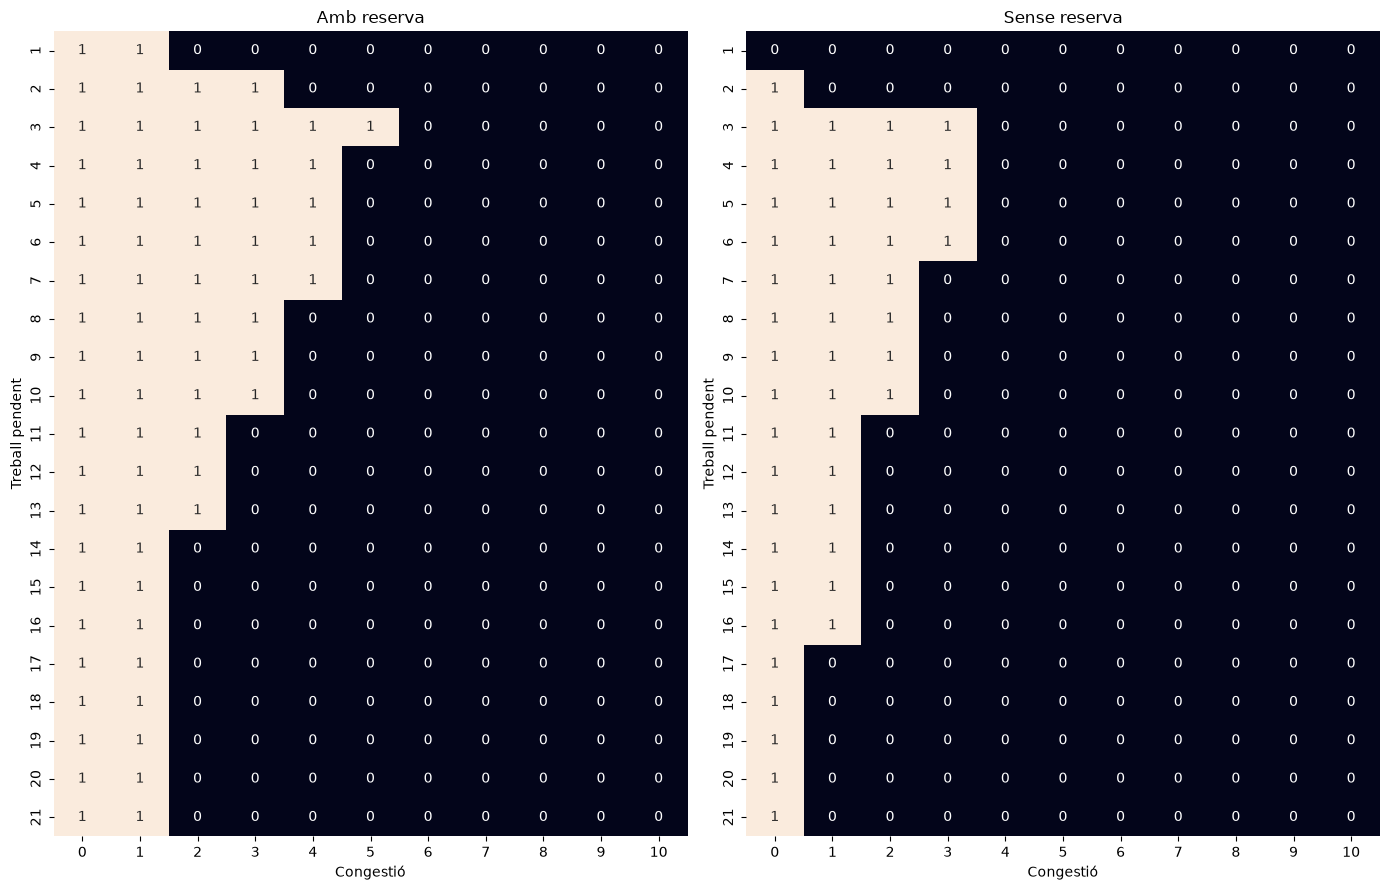

In [63]:
print("Politica optima (γ = 1), El mateix resultat que abans")
print_policy_opt(optimal_policy)

In [64]:
def n_errors(pol, ref):
    return sum(pol[s] != ref[s] for s in ref)

print("Estats on difereixen les òptimes (γ=1 vs γ=0.1):", n_errors(opt_g01, optimal_policy))

refs = {1.0: optimal_policy, 0.1: opt_g01}
rows = []
for algo in ("mc", "sarsa"):
    for gamma in (1.0, 0.1):
        for seed in (42, 123, 2026):
            pol = policies[(algo, 300_000, gamma, None, seed)]
            rows.append({"algo": algo, "gamma": gamma,
                         "errors_vs_gamma1": n_errors(pol, optimal_policy),
                         "errors_vs_own_opt": n_errors(pol, refs[gamma]),
                         "express_share": np.mean(list(pol.values()))})
tab52 = pd.DataFrame(rows).groupby(["algo", "gamma"]).agg(["mean", "std"]).round(3)
tab52



Estats on difereixen les òptimes (γ=1 vs γ=0.1): 110


errors_vs_gamma1        errors_vs_own_opt        express_share  \
                        mean    std              mean    std          mean   
algo  gamma                                                                  
mc    0.1            127.333  2.082            90.000  4.583         0.110   
      1.0            146.333  9.018           146.333  9.018         0.208   
sarsa 0.1            119.000  2.000            41.667  4.163         0.139   
      1.0            124.667  4.041           124.667  4.041         0.219   

                    
               std  
algo  gamma         
mc    0.1    0.014  
      1.0    0.026  
sarsa 0.1    0.000  
      1.0    0.006

Politica optima (γ = 0.1)


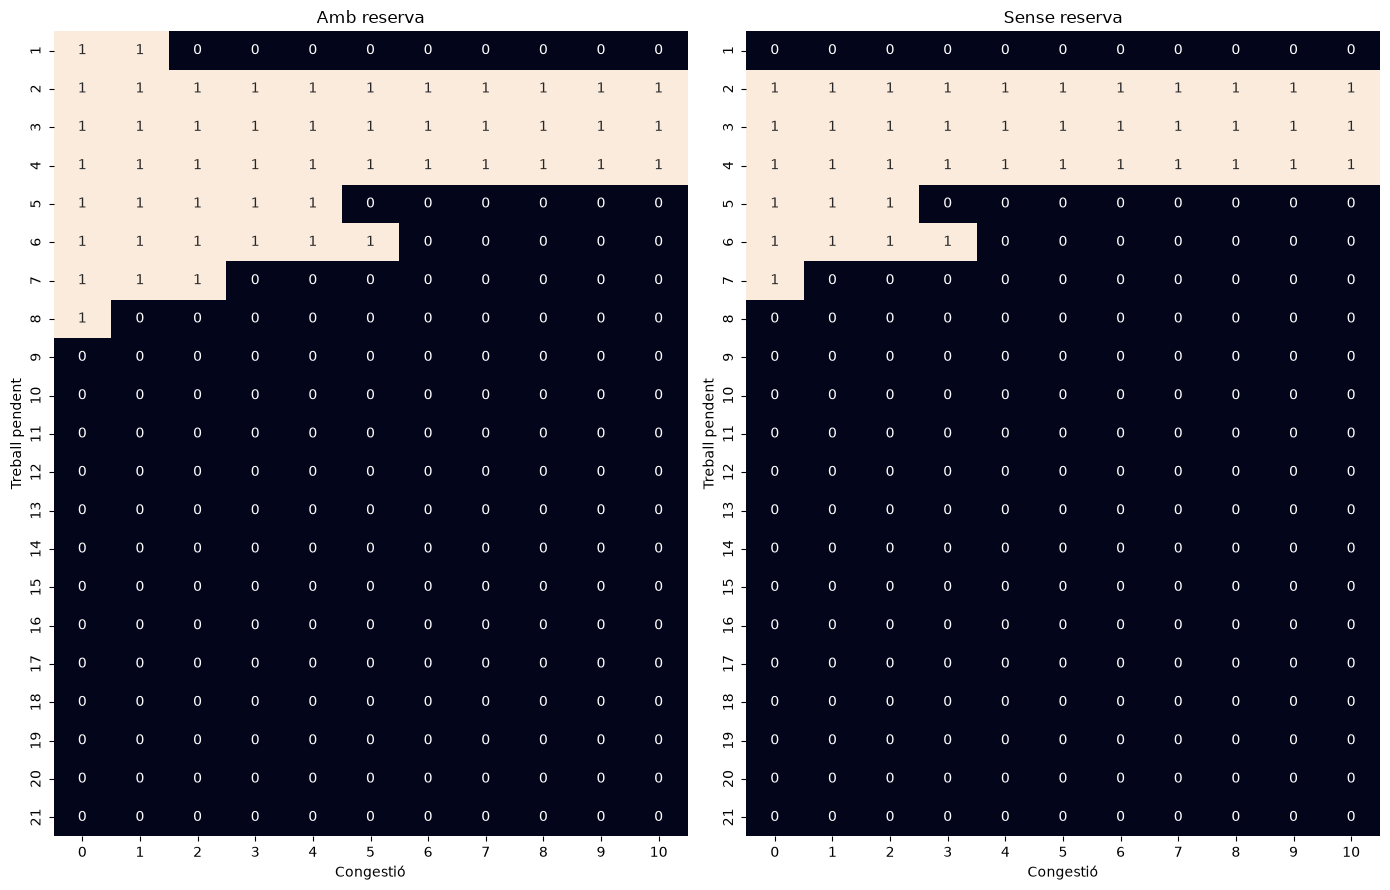

In [65]:
print("Politica optima (γ = 0.1)")
print_policy_opt(opt_g01)

<div style="background-color: #fcf2f2; border-color: #dfb5b4; border-left: 5px solid #dfb5b4; padding: 0.5em;">
<strong>CONCLUSIONS:</strong>
<br>

Amb gamma = 0,1 la política canvia segons la distancia a la finalitzacio, quan estem lluny de l'objectiu l'agent gairebe no utilitza la ruta EXPRESS, i a prop de l'objectiu augmenta clarament l'us respecte a gamma = 1 (la referencia del 2.1)

Com que la recompensa de +1 per completar l'expedició queda a diversos passos, el seu valor actual es gairebé nul, mentre que el −1 d'una incidencia es immediat, per tant l'agent prioritza la ruta SAFE, ja que els retards no tenen cost. 

La recompensa mitjana es lleugerament inferior, com esperat perque s'avalua sense descompte i l'agent optimitza una altra. Per la mateixa raó, els errors respecte a la politica optima amb gamma = 1 no son directament comparables, ja que les dues politiques optimes ja difereixen en molts estats. 

Finalment, en els estats llunyans els valors de Q són propers a zero i el desempat cap a la ruta segura coincideix amb la política de referència.

<br>


</div>

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Exercici 5.3 - Influència de la taxa d'aprenentatge</strong> (0,5 punts)

Entreneu l'algoritme *SARSA* amb 300.000 episodis i 3 execucions per a cadascun dels valors següents de *learning rate*: 0.001, 0.01, 0.1 i 0.9, i amb la resta de paràmetres iguals que en l'exercici 4. <br>
Analitzeu les diferències respecte dels resultats obtinguts en la pregunta 1 d'aquest exercici per al mateix nombre d'episodis d'entrenament (300.000 episodis), en termes de:<br>
- Nombre d'errors respecte de la política òptima.<br>
- Recompensa acumulada en 100.000 episodis executats una vegada l'algoritme ha estat entrenat.</div>


In [66]:
rows_53 = []
for alpha in (0.01, 0.1, 0.9):
    for seed in (42, 123, 2026):
        rows_53.append(experiment("sarsa", 300_000, seed, alpha=alpha))
df53 = pd.DataFrame(rows_53)

In [67]:
base = df[(df.algo == "sarsa") & (df.episodes == 300_000)].assign(alpha=0.001)
cmp53 = pd.concat([base, df53]).groupby("alpha")[["errors", "mean_return"]].agg(["mean", "std"])
cmp53

errors            mean_return          
             mean        std        mean       std
alpha                                             
0.001  124.666667   4.041452     0.40613  0.001958
0.010   92.666667   3.785939     0.42217  0.003137
0.100  162.666667  13.316656     0.39247  0.001223
0.900  200.333333  13.650397     0.37562  0.003411

<div style="background-color: #fcf2f2; border-color: #dfb5b4; border-left: 5px solid #dfb5b4; padding: 0.5em;">
<strong>CONCLUSIONS:</strong>
<br>

La taxa d'aprenentatge te un valor intermedi optim, entre els valors provats, alpha = 0,01 obté els menys errors i la millor recompensa mitjana, pel contrari tant alpha = 0,001 com alpha = 0,1 i 0,9 empitjoren els dos indicadors.

Amb alpha massa petita l'aprenentatge es massa lent per a 300.000 episodis, cada actualització mou Q molt poc i els parells estat-acció menys visitats gairebé no s'actualitzen. 

Pel contrari, quan alpha es gran, cada actualització s'acosta molt a l'objectiu de l'últim pas, que és molt soroll, de manera que Q varia i l'acció greedy canvia en estats amb valors propers. 

Cap valor arriba a la política optima, l'SARSA aprèn el valor de la política greedy epsilon que segueix (eps = 0,2), i només hem provat quatre valors, de manera que l'alpha optima podria ser entre 0,001 i 0,1.

<br>


</div>

<div style="background-color: #c3fac4; border-color: #dfb5b4; border-left: 5px solid #dfb5b4; padding: 0.5em;">
<strong>Fonts:</strong>
<br><br>
Indiqueu aquí les fonts utilitzades en l'elaboració d'aquest exercici.

- S'ha utilitzat Claude Sonnet 5.5 (Anthropic) com a suport per a la correcció lingüística i d'estil dels comentaris. La implementació del codi i l'anàlisi són elaborats per l'estudiant
<br>
</div>